# UK Road Safety Analytics: Big Data Exploration, Statistical Analysis & Interactive Dashboard

**A reproducible, end-to-end road-safety analytics project using PySpark, Python, statistical testing, geospatial visualization and machine learning.**

---

## Project purpose

This notebook examines reported personal-injury road collisions in Great Britain using the Kaggle **UK Road Safety: Traffic Accidents and Vehicles** dataset. It connects accident-level circumstances with vehicle-level information where the two files can be reliably matched.

The notebook is designed to go beyond basic charting. It validates the source data, documents data quality, engineers time and severity features, studies patterns across year, month, weekday, hour, weather, lighting, road type, speed limit and location, and then explores driver and vehicle characteristics. It also includes statistical association tests, an optional severity-classification model, and a final interactive dashboard.

## 1. Install libraries and import dependencies

This project uses PySpark to read and aggregate the multi-million-row CSV files. Pandas is used only after Spark has reduced the data to compact summaries or samples. Matplotlib is used for standalone, publication-style charts; Plotly and Folium support interactive outputs; SciPy supports statistical tests; scikit-learn supports an optional model evaluation.

In [1]:
import sys
import subprocess

PACKAGES = ["pyspark", "kaggle", "plotly", "folium", "scipy", "scikit-learn"]
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *PACKAGES],
    check=True
)

import os
import re
import json
import math
import calendar
import warnings
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import folium
from folium.plugins import HeatMap

from scipy.stats import chi2_contingency, spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Consistent chart defaults. Individual cells may override figure size.
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.25,
    "font.family": "DejaVu Sans"
})

print("Libraries installed and imported.")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)

Libraries installed and imported.
Python: 3.13.18
Pandas: 2.2.3


## 2. Authenticate with Kaggle and download the dataset

The dataset is downloaded directly into the Colab runtime. Enter your Kaggle API token when prompted. The token is kept in the current runtime environment only; it is not written into the notebook. If both CSV files already exist in the project folder, the download is skipped.

In [2]:
# Kaggle API token is requested interactively and is not displayed.
if not os.environ.get("KAGGLE_API_TOKEN"):
    os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ").strip()

if not os.environ["KAGGLE_API_TOKEN"]:
    raise ValueError("A Kaggle API token is required to download the dataset.")

PROJECT_DIR = Path("/content/uk_road_safety_project")
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

ACCIDENT_PATH = DATA_DIR / "Accident_Information.csv"
VEHICLE_PATH = DATA_DIR / "Vehicle_Information.csv"

if not (ACCIDENT_PATH.exists() and VEHICLE_PATH.exists()):
    import shutil
    kaggle_exe = shutil.which("kaggle")
    if kaggle_exe is None:
        raise RuntimeError("Kaggle CLI was not installed successfully. Restart the cell.")

    subprocess.run(
        [kaggle_exe, "datasets", "download",
         "-d", "tsiaras/uk-road-safety-accidents-and-vehicles",
         "-p", str(DATA_DIR)],
        check=True
    )

    zip_files = list(DATA_DIR.glob("*.zip"))
    if not zip_files:
        raise FileNotFoundError("Kaggle download completed but no ZIP archive was found.")

    import zipfile
    for zip_path in zip_files:
        with zipfile.ZipFile(zip_path, "r") as archive:
            archive.extractall(DATA_DIR)

if not ACCIDENT_PATH.exists() or not VEHICLE_PATH.exists():
    found = [p.name for p in DATA_DIR.rglob("*.csv")]
    raise FileNotFoundError(
        "Expected CSV files were not found. CSV files detected: " + str(found)
    )

# Remove the API token from the environment after authentication/download.
os.environ.pop("KAGGLE_API_TOKEN", None)

print("Dataset files are ready:")
for path in [ACCIDENT_PATH, VEHICLE_PATH]:
    print(f"- {path.name}: {path.stat().st_size / (1024**2):,.1f} MB")

Enter your Kaggle API token: ··········
Dataset files are ready:
- Accident_Information.csv: 672.8 MB
- Vehicle_Information.csv: 614.6 MB


## 3. Initialize Spark

Spark is used for scalable CSV ingestion, transformations, joins and grouped calculations. In Colab, `local[*]` uses the CPU cores assigned to the current runtime. This is local multi-core Spark processing, not a multi-machine cluster.

In [3]:
# Install Java only if the runtime does not already provide it.
if subprocess.run(["bash", "-lc", "command -v java >/dev/null"], check=False).returncode != 0:
    subprocess.run(
        ["bash", "-lc", "apt-get update -qq && apt-get install -y -qq openjdk-17-jre-headless"],
        check=True
    )

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.storagelevel import StorageLevel

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("UK_Road_Safety_Analytics")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.default.parallelism", "8")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Default parallelism:", spark.sparkContext.defaultParallelism)

Spark version: 4.0.5
Default parallelism: 8


## 4. Load the accident and vehicle files

All columns are initially read as strings. This avoids uncontrolled type inference and lets the cleaning section explicitly parse numeric and date fields. The source file names and row counts are recorded for reproducibility.

In [4]:
accident_raw = (
    spark.read.option("header", True)
    .option("inferSchema", False)
    .option("mode", "PERMISSIVE")
    .option("encoding", "UTF-8")
    .csv(str(ACCIDENT_PATH))
)

vehicle_raw = (
    spark.read.option("header", True)
    .option("inferSchema", False)
    .option("mode", "PERMISSIVE")
    .option("encoding", "UTF-8")
    .csv(str(VEHICLE_PATH))
)

accident_rows = accident_raw.count()
vehicle_rows = vehicle_raw.count()

print(f"Accident records: {accident_rows:,} | columns: {len(accident_raw.columns)}")
print(f"Vehicle records:  {vehicle_rows:,} | columns: {len(vehicle_raw.columns)}")
print("Accident years in source:", accident_raw.select("Year").distinct().count(), "distinct values")
print("Vehicle years in source:", vehicle_raw.select("Year").distinct().count(), "distinct values")

Accident records: 2,047,256 | columns: 34
Vehicle records:  2,177,205 | columns: 24
Accident years in source: 13 distinct values
Vehicle years in source: 13 distinct values


## 5. Inspect the source schemas

The accident file describes one collision per `Accident_Index`; the vehicle file describes individual vehicle involvements. `Accident_Index` is the shared identifier. The two files should not be treated as if they had the same grain.

In [5]:
print("ACCIDENT FILE SCHEMA")
accident_raw.printSchema()
print("VEHICLE FILE SCHEMA")
vehicle_raw.printSchema()

print("Accident sample (3 rows):")
accident_raw.select(
    "Accident_Index", "Date", "Time", "Accident_Severity",
    "Number_of_Casualties", "Number_of_Vehicles", "Weather_Conditions"
).show(3, truncate=35)

print("Vehicle sample (3 rows):")
vehicle_raw.select(
    "Accident_Index", "Vehicle_Reference", "Vehicle_Type",
    "Age_Band_of_Driver", "Sex_of_Driver", "Age_of_Vehicle"
).show(3, truncate=35)

ACCIDENT FILE SCHEMA
root
 |-- Accident_Index: string (nullable = true)
 |-- 1st_Road_Class: string (nullable = true)
 |-- 1st_Road_Number: string (nullable = true)
 |-- 2nd_Road_Class: string (nullable = true)
 |-- 2nd_Road_Number: string (nullable = true)
 |-- Accident_Severity: string (nullable = true)
 |-- Carriageway_Hazards: string (nullable = true)
 |-- Date: string (nullable = true)
 |-- Day_of_Week: string (nullable = true)
 |-- Did_Police_Officer_Attend_Scene_of_Accident: string (nullable = true)
 |-- Junction_Control: string (nullable = true)
 |-- Junction_Detail: string (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Light_Conditions: string (nullable = true)
 |-- Local_Authority_(District): string (nullable = true)
 |-- Local_Authority_(Highway): string (nullable = true)
 |-- Location_Easting_OSGR: string (nullable = true)
 |-- Location_Northing_OSGR: string (nullable = true)
 |-- Longitude: string (nullable = true)
 |-- LSOA_of_Accident_Location: string (nu

## 6. Source coverage and row-grain validation

This section establishes the period covered by each file and the meaning of its rows. The accident table is accident-level; the vehicle table is vehicle-involvement-level. The annual counts are used as coverage information, not as a direct road-risk measure.

In [6]:
accident_year_summary = (
    accident_raw.groupBy("Year").count()
    .withColumn("Year_num", F.col("Year").cast("int"))
    .orderBy("Year_num")
)
vehicle_year_summary = (
    vehicle_raw.groupBy("Year").count()
    .withColumn("Year_num", F.col("Year").cast("int"))
    .orderBy("Year_num")
)

accident_year_pd = accident_year_summary.select("Year_num", "count").toPandas()
vehicle_year_pd = vehicle_year_summary.select("Year_num", "count").toPandas()

print("Accident period:", accident_year_pd.Year_num.min(), "to", accident_year_pd.Year_num.max())
print("Vehicle period:", vehicle_year_pd.Year_num.min(), "to", vehicle_year_pd.Year_num.max())
print("Accident records are at accident grain; vehicle records are at vehicle-involvement grain.")

Accident period: 2005 to 2017
Vehicle period: 2004 to 2016
Accident records are at accident grain; vehicle records are at vehicle-involvement grain.


## 7. Data cleaning and feature engineering

The source uses text values such as `Data missing or out of range`, `NA`, and `None`. These values are not all equivalent. This notebook maps null, blank and the explicit missing-data phrase to `Unknown`; it preserves `NA` and `None` as separate source categories because they may mean not applicable or no recorded hazard. Numeric fields are safely cast; unparseable values become null.

In [7]:
def normalize_text_columns(df):
    """Trim strings and normalize explicit missing markers without erasing NA/None semantics."""
    result = df
    for name, dtype in df.dtypes:
        if dtype == "string":
            c = F.col(f"`{name.replace('`', '``')}`")
            cleaned = F.trim(c)
            result = result.withColumn(
                name,
                F.when(c.isNull() | (cleaned == ""), F.lit("Unknown"))
                 .when(F.lower(cleaned) == "data missing or out of range", F.lit("Unknown"))
                 .otherwise(cleaned)
            )
    return result

accidents = normalize_text_columns(accident_raw)
vehicles = normalize_text_columns(vehicle_raw)

# Numeric columns in accident-level file.
accident_numeric_types = {
    "Year": "int",
    "Latitude": "double",
    "Longitude": "double",
    "Location_Easting_OSGR": "double",
    "Location_Northing_OSGR": "double",
    "Number_of_Casualties": "int",
    "Number_of_Vehicles": "int",
    "Speed_limit": "int"
}
for col_name, dtype in accident_numeric_types.items():
    accidents = accidents.withColumn(col_name, F.col(col_name).cast(dtype))

accidents = (
    accidents
    .withColumn("Accident_Date", F.to_date("Date", "yyyy-MM-dd"))
    .withColumn("Month", F.month("Accident_Date"))
    .withColumn("Month_Name", F.date_format("Accident_Date", "MMMM"))
    .withColumn("Hour", F.substring("Time", 1, 2).cast("int"))
    .withColumn("Is_Severe", F.when(F.col("Accident_Severity").isin("Fatal", "Serious"), 1)
                              .when(F.col("Accident_Severity") == "Slight", 0))
    .withColumn("Severity_Order", F.when(F.col("Accident_Severity") == "Fatal", 3)
                                   .when(F.col("Accident_Severity") == "Serious", 2)
                                   .when(F.col("Accident_Severity") == "Slight", 1))
)

# Numeric columns in vehicle-level file.
vehicle_numeric_types = {
    "Year": "int",
    "Age_of_Vehicle": "double",
    "Engine_Capacity_.CC.": "double",
    "Vehicle_Reference": "int",
    "Driver_IMD_Decile": "int"
}
for col_name, dtype in vehicle_numeric_types.items():
    vehicles = vehicles.withColumn(col_name, F.col(f"`{col_name}`").cast(dtype))

# Persist cleaned DataFrames because later cells reuse them repeatedly.
accidents = accidents.persist(StorageLevel.MEMORY_AND_DISK)
vehicles = vehicles.persist(StorageLevel.MEMORY_AND_DISK)
accident_clean_count = accidents.count()
vehicle_clean_count = vehicles.count()

print(f"Cleaned accident records: {accident_clean_count:,}")
print(f"Cleaned vehicle records: {vehicle_clean_count:,}")
print("Derived fields: Accident_Date, Month, Month_Name, Hour, Is_Severe, Severity_Order")

Cleaned accident records: 2,047,256
Cleaned vehicle records: 2,177,205
Derived fields: Accident_Date, Month, Month_Name, Hour, Is_Severe, Severity_Order


## 8. Descriptive overview: key metrics

The overview summarizes the scale of the two source files and their time coverage. It is a compact quality checkpoint before detailed visual analysis.

In [8]:
accident_overview = accidents.agg(
    F.count("*").alias("Accident_Records"),
    F.countDistinct("Accident_Index").alias("Unique_Accidents"),
    F.min("Year").alias("First_Accident_Year"),
    F.max("Year").alias("Last_Accident_Year"),
    F.sum("Number_of_Casualties").alias("Recorded_Casualties"),
    F.avg("Number_of_Casualties").alias("Mean_Casualties_Per_Accident")
).first().asDict()

vehicle_overview = vehicles.agg(
    F.count("*").alias("Vehicle_Involvements"),
    F.countDistinct("Accident_Index").alias("Unique_Accident_IDs_In_Vehicle_File"),
    F.min("Year").alias("First_Vehicle_Year"),
    F.max("Year").alias("Last_Vehicle_Year")
).first().asDict()

print("ACCIDENT DATASET")
for metric, value in accident_overview.items():
    print(f"{metric}: {value}")
print("\nVEHICLE DATASET")
for metric, value in vehicle_overview.items():
    print(f"{metric}: {value}")

ACCIDENT DATASET
Accident_Records: 2047256
Unique_Accidents: 2047256
First_Accident_Year: 2005
Last_Accident_Year: 2017
Recorded_Casualties: 2755286
Mean_Casualties_Per_Accident: 1.3458434118644664

VEHICLE DATASET
Vehicle_Involvements: 2177205
Unique_Accident_IDs_In_Vehicle_File: 1488981
First_Vehicle_Year: 2004
Last_Vehicle_Year: 2016


## 9. Missing-value profile: accident information

**What this graph shows:** the 15 accident-level fields with the highest share of explicit missing markers. The denominator is all accident records. `NA` and `None` are preserved as source categories and are not automatically counted as missing.

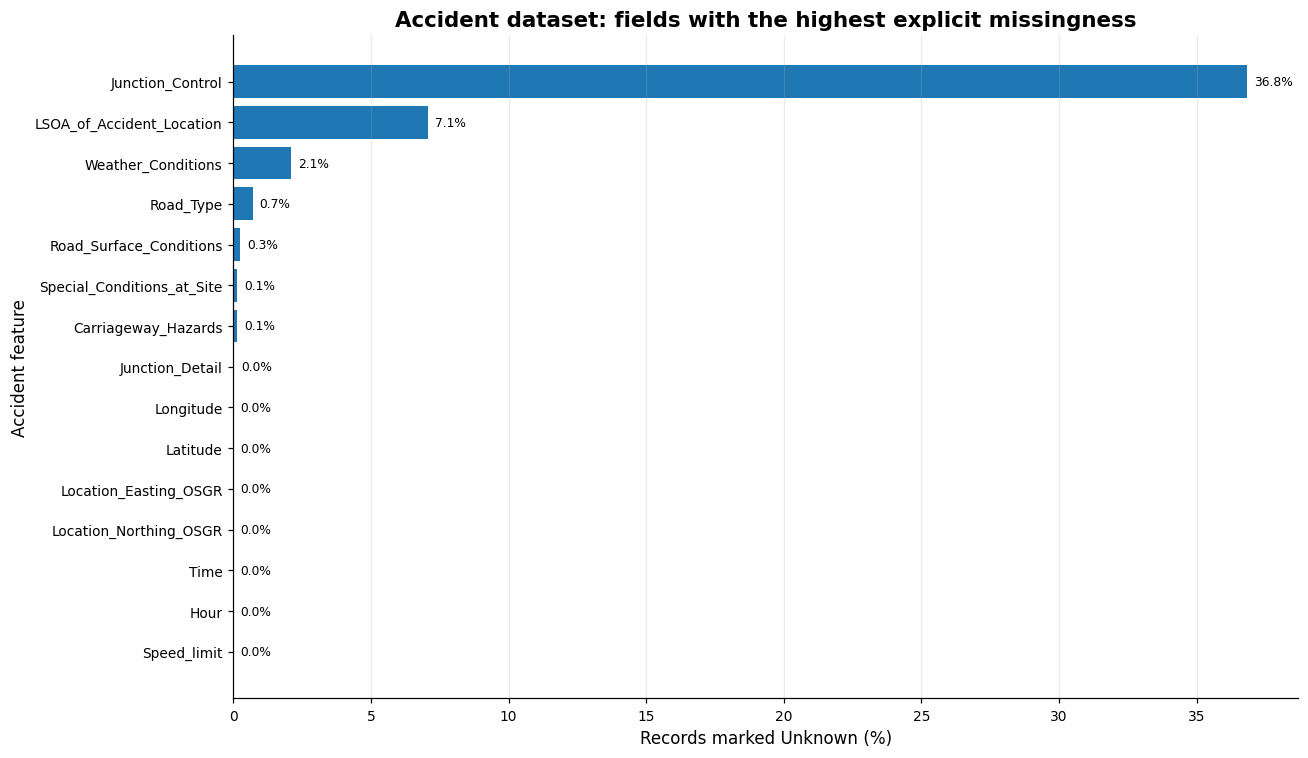

Interpretation: fields at the top have the weakest explicit completeness; a high missing share is a reason to qualify later comparisons, not automatically delete the field.


In [9]:
missing_exprs = []
for name in accidents.columns:
    c = F.col(f"`{name.replace('`', '``')}`")
    condition = c.isNull() | (F.trim(c.cast("string")) == "") | (F.lower(F.trim(c.cast("string"))) == "unknown")
    missing_exprs.append(F.sum(F.when(condition, 1).otherwise(0)).alias(name))
missing_values = accidents.agg(*missing_exprs).first().asDict()
missing_acc_pd = pd.DataFrame([
    {"Field": k, "Missing_Count": int(v or 0), "Missing_Percent": 100 * (v or 0) / accident_clean_count}
    for k, v in missing_values.items()
]).sort_values("Missing_Percent", ascending=False).head(15).sort_values("Missing_Percent")

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(missing_acc_pd["Field"], missing_acc_pd["Missing_Percent"])
for i, v in enumerate(missing_acc_pd["Missing_Percent"]):
    ax.text(v + 0.25, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_title("Accident dataset: fields with the highest explicit missingness")
ax.set_xlabel("Records marked Unknown (%)")
ax.set_ylabel("Accident feature")
ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: fields at the top have the weakest explicit completeness; a high missing share is a reason to qualify later comparisons, not automatically delete the field.")

## 10. Missing-value profile: vehicle information

**What this graph shows:** the 15 vehicle-level fields with the highest share of explicit missing markers. This matters because driver and vehicle comparisons depend on these fields being sufficiently complete.

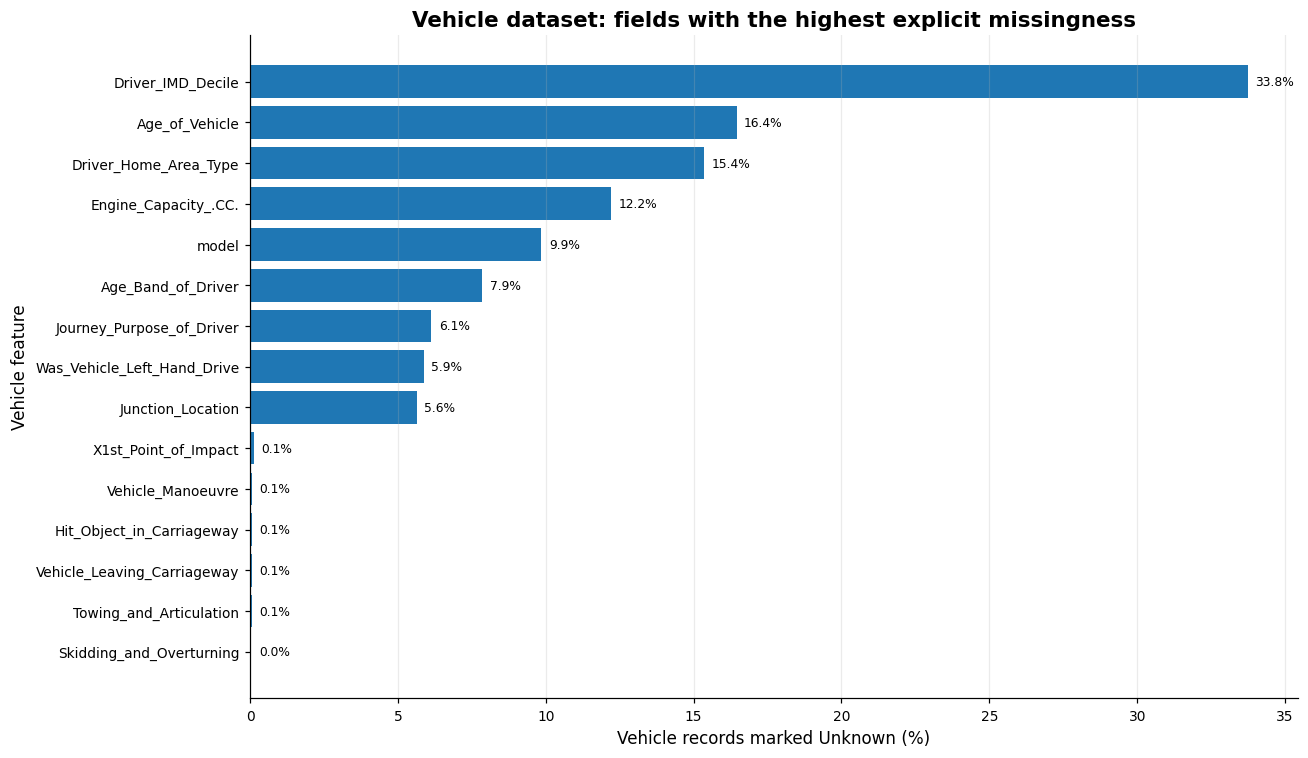

Interpretation: driver and vehicle features with high missingness should be analyzed with their valid-record denominator reported.


In [10]:
missing_exprs = []
for name in vehicles.columns:
    c = F.col(f"`{name.replace('`', '``')}`")
    condition = c.isNull() | (F.trim(c.cast("string")) == "") | (F.lower(F.trim(c.cast("string"))) == "unknown")
    missing_exprs.append(F.sum(F.when(condition, 1).otherwise(0)).alias(name))
missing_values = vehicles.agg(*missing_exprs).first().asDict()
missing_veh_pd = pd.DataFrame([
    {"Field": k, "Missing_Count": int(v or 0), "Missing_Percent": 100 * (v or 0) / vehicle_clean_count}
    for k, v in missing_values.items()
]).sort_values("Missing_Percent", ascending=False).head(15).sort_values("Missing_Percent")

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(missing_veh_pd["Field"], missing_veh_pd["Missing_Percent"])
for i, v in enumerate(missing_veh_pd["Missing_Percent"]):
    ax.text(v + 0.25, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_title("Vehicle dataset: fields with the highest explicit missingness")
ax.set_xlabel("Vehicle records marked Unknown (%)")
ax.set_ylabel("Vehicle feature")
ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: driver and vehicle features with high missingness should be analyzed with their valid-record denominator reported.")

## 11. Duplicate-key audit

Accident identifiers should be unique in the accident file. In the vehicle file, multiple rows per accident are expected, so the meaningful vehicle key is the combination of `Accident_Index` and `Vehicle_Reference`. This cell checks those keys rather than incorrectly treating repeated accident IDs in the vehicle file as duplicates.

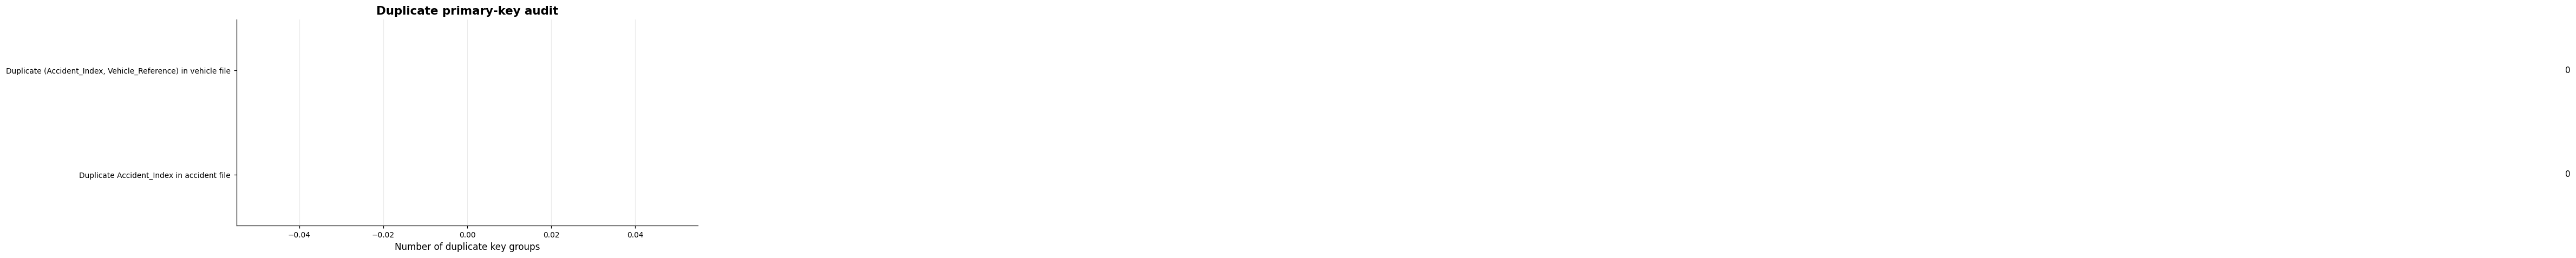

Accident key duplicate groups: 0
Vehicle composite-key duplicate groups: 0
Interpretation: repeated Accident_Index values in the vehicle file are normal; duplicate composite vehicle keys are the warning condition.


In [11]:
accident_key_duplicates = (
    accidents.groupBy("Accident_Index").count().filter(F.col("count") > 1).count()
)
vehicle_key_duplicates = (
    vehicles.filter(F.col("Vehicle_Reference").isNotNull())
    .groupBy("Accident_Index", "Vehicle_Reference")
    .count().filter(F.col("count") > 1).count()
)

key_audit = pd.DataFrame({
    "Key check": ["Duplicate Accident_Index in accident file", "Duplicate (Accident_Index, Vehicle_Reference) in vehicle file"],
    "Duplicate key groups": [accident_key_duplicates, vehicle_key_duplicates]
})

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(key_audit["Key check"], key_audit["Duplicate key groups"])
for i, val in enumerate(key_audit["Duplicate key groups"]):
    ax.text(max(val, 0) + 0.5, i, f"{val:,}", va="center")
ax.set_title("Duplicate primary-key audit")
ax.set_xlabel("Number of duplicate key groups")
ax.grid(axis="x")
plt.tight_layout(); plt.show()
print(f"Accident key duplicate groups: {accident_key_duplicates:,}")
print(f"Vehicle composite-key duplicate groups: {vehicle_key_duplicates:,}")
print("Interpretation: repeated Accident_Index values in the vehicle file are normal; duplicate composite vehicle keys are the warning condition.")

## 12. Accident-to-vehicle linkage coverage

**What this graph shows:** the share of accident IDs in each overlapping year that have at least one matching vehicle record. The 2017 accident year is excluded because the supplied vehicle file ends in 2016. This is a file-linkage completeness measure, not a collision risk rate.

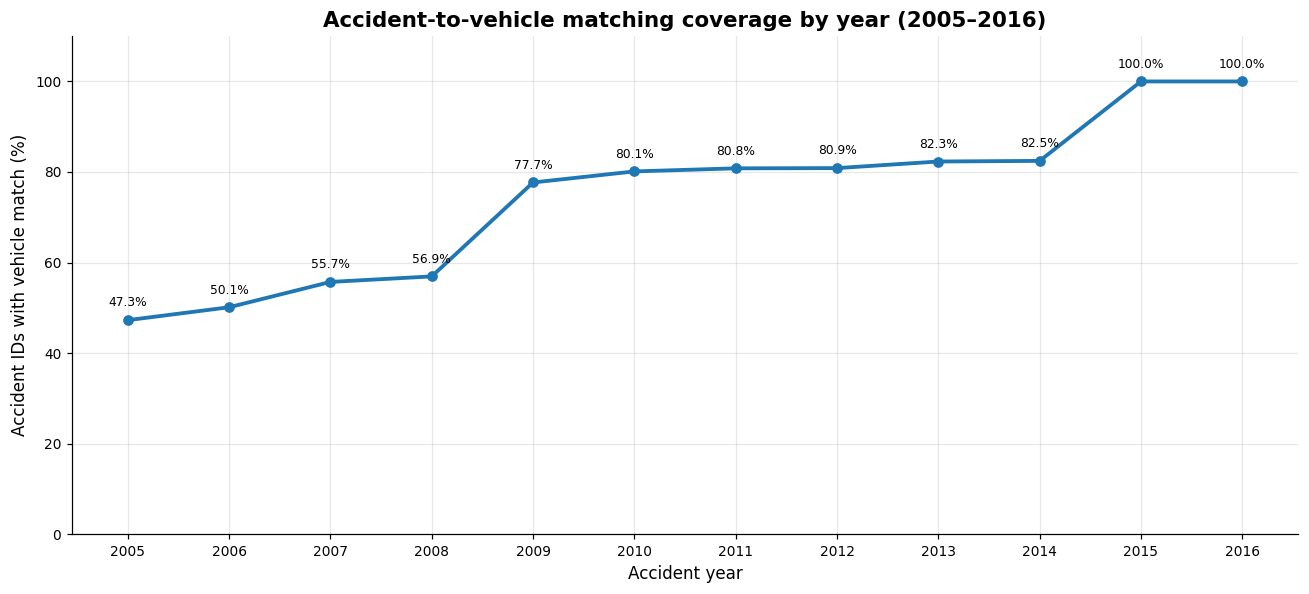

Interpretation: lower coverage means fewer accident IDs in this Kaggle vehicle extract link to the accident file. Vehicle-based results must be described as matched-subset results.


In [12]:
accident_keys = accidents.select("Accident_Index", F.col("Year").alias("Accident_Year"))
vehicle_keys = vehicles.groupBy("Accident_Index").agg(
    F.count("*").alias("Vehicle_Records"),
    F.min("Year").alias("Vehicle_Year"),
    F.countDistinct("Year").alias("Vehicle_Year_Count")
)
matched_keys = accident_keys.join(vehicle_keys, "Accident_Index", "inner")

coverage_pd = (
    accident_keys.filter(F.col("Accident_Year").between(2005, 2016))
    .groupBy("Accident_Year").agg(F.countDistinct("Accident_Index").alias("All_Accidents"))
    .join(
        matched_keys.groupBy("Accident_Year").agg(F.countDistinct("Accident_Index").alias("Matched_Accidents")),
        "Accident_Year", "left"
    ).fillna(0, subset=["Matched_Accidents"])
    .withColumn("Coverage_Percent", 100 * F.col("Matched_Accidents") / F.col("All_Accidents"))
    .orderBy("Accident_Year").toPandas()
)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(coverage_pd["Accident_Year"], coverage_pd["Coverage_Percent"], marker="o", linewidth=2.5)
for _, row in coverage_pd.iterrows():
    ax.annotate(f"{row['Coverage_Percent']:.1f}%", (row["Accident_Year"], row["Coverage_Percent"]),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
ax.set_title("Accident-to-vehicle matching coverage by year (2005–2016)")
ax.set_xlabel("Accident year")
ax.set_ylabel("Accident IDs with vehicle match (%)")
ax.set_ylim(0, 110); ax.set_xticks(coverage_pd["Accident_Year"]); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Interpretation: lower coverage means fewer accident IDs in this Kaggle vehicle extract link to the accident file. Vehicle-based results must be described as matched-subset results.")

## 13. Build the analysis-ready matched vehicle table

This creates a **vehicle-grain** table: each row represents one vehicle involved in a matched accident. It carries selected accident attributes such as year, severity, weather and road type onto the corresponding vehicle row. The table is useful for vehicle-level distributions and must not be counted as unique accidents.

In [13]:
accident_context = accidents.select(
    "Accident_Index", F.col("Year").alias("Accident_Year"), "Accident_Severity", "Is_Severe",
    "Weather_Conditions", "Light_Conditions", "Road_Surface_Conditions",
    "Road_Type", "Speed_limit", "Urban_or_Rural_Area",
    "Number_of_Casualties", "Number_of_Vehicles", "Hour", "Month"
)

vehicles_overlap = vehicles.filter(F.col("Year").between(2005, 2016))
vehicle_joined = vehicles_overlap.join(accident_context, "Accident_Index", "inner")

print(f"Vehicle involvements in matched analysis: {vehicle_joined.count():,}")
print(f"Unique accidents represented: {vehicle_joined.select('Accident_Index').distinct().count():,}")
print("Grain: one row per matched vehicle involvement; do not interpret this row count as accident count.")

Vehicle involvements in matched analysis: 2,058,408
Unique accidents represented: 1,389,724
Grain: one row per matched vehicle involvement; do not interpret this row count as accident count.


## 14. Annual reported accident trend

**What this graph shows:** the number of recorded personal-injury accidents in each year from 2005 to 2017. A three-year moving average is added to make the longer-term direction easier to see. The measure is an accident count, not a traffic-exposure-adjusted rate.

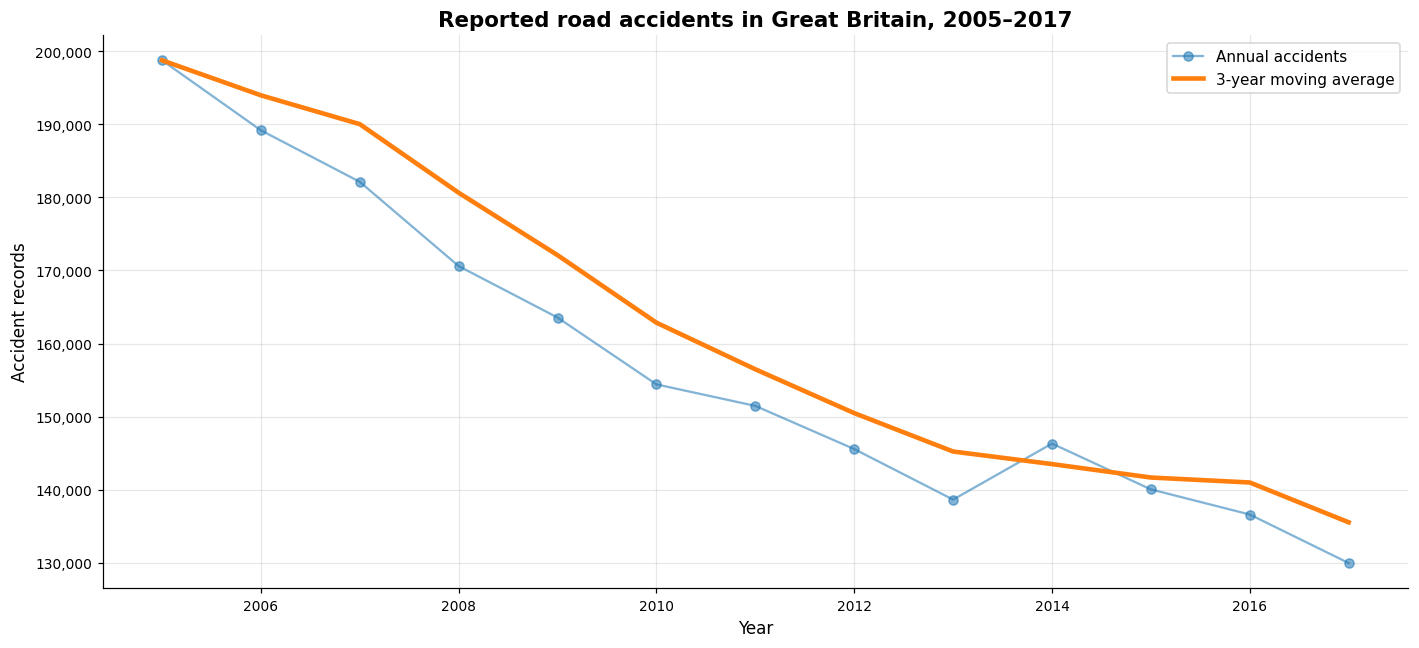

Interpretation: recorded accidents changed by -34.6% between 2005 and 2017. Counts alone do not establish that per-journey risk changed by the same amount.


In [14]:
annual_accidents = accidents.groupBy("Year").agg(F.countDistinct("Accident_Index").alias("Accidents")).orderBy("Year").toPandas()
annual_accidents["MA_3Y"] = annual_accidents["Accidents"].rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(annual_accidents["Year"], annual_accidents["Accidents"], marker="o", alpha=.55, label="Annual accidents")
ax.plot(annual_accidents["Year"], annual_accidents["MA_3Y"], linewidth=3, label="3-year moving average")
ax.set_title("Reported road accidents in Great Britain, 2005–2017")
ax.set_xlabel("Year"); ax.set_ylabel("Accident records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

first = annual_accidents.iloc[0]; last = annual_accidents.iloc[-1]
change = (last["Accidents"] / first["Accidents"] - 1) * 100
print(f"Interpretation: recorded accidents changed by {change:.1f}% between {int(first['Year'])} and {int(last['Year'])}. Counts alone do not establish that per-journey risk changed by the same amount.")

## 15. Overall accident-severity composition

**What this graph shows:** the share of records classified as Fatal, Serious or Slight across the complete accident period. The percentages use the accident file as the denominator. This is a composition chart, not a comparison of severity rates across road-user exposure.

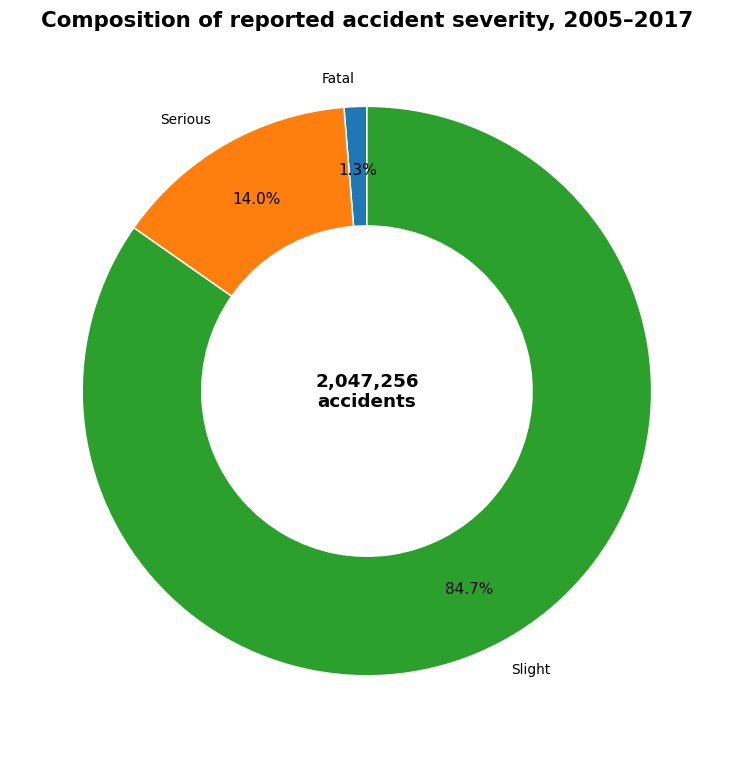

Interpretation: the chart describes the proportion of reported accident records in each severity class. Fatal and serious categories are relatively uncommon, so their rates should be shown with appropriate denominators in later comparisons.


In [15]:
severity_pd = (
    accidents.groupBy("Accident_Severity").count()
    .filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .orderBy("Accident_Severity").toPandas()
)
severity_pd["Percent"] = 100 * severity_pd["count"] / severity_pd["count"].sum()

fig, ax = plt.subplots(figsize=(8, 7))
wedges, texts, autotexts = ax.pie(
    severity_pd["count"], labels=severity_pd["Accident_Severity"],
    autopct="%1.1f%%", startangle=90, pctdistance=.78,
    wedgeprops={"width": .42, "edgecolor": "white"}
)
ax.text(0, 0, f"{severity_pd['count'].sum():,}\naccidents", ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_title("Composition of reported accident severity, 2005–2017")
plt.tight_layout(); plt.show()
print("Interpretation: the chart describes the proportion of reported accident records in each severity class. Fatal and serious categories are relatively uncommon, so their rates should be shown with appropriate denominators in later comparisons.")

## 16. Severity trends over time

**What this graph shows:** annual counts of Fatal, Serious and Slight accidents as separate lines. This identifies whether the broad fall or rise in total accidents is shared by each severity category.

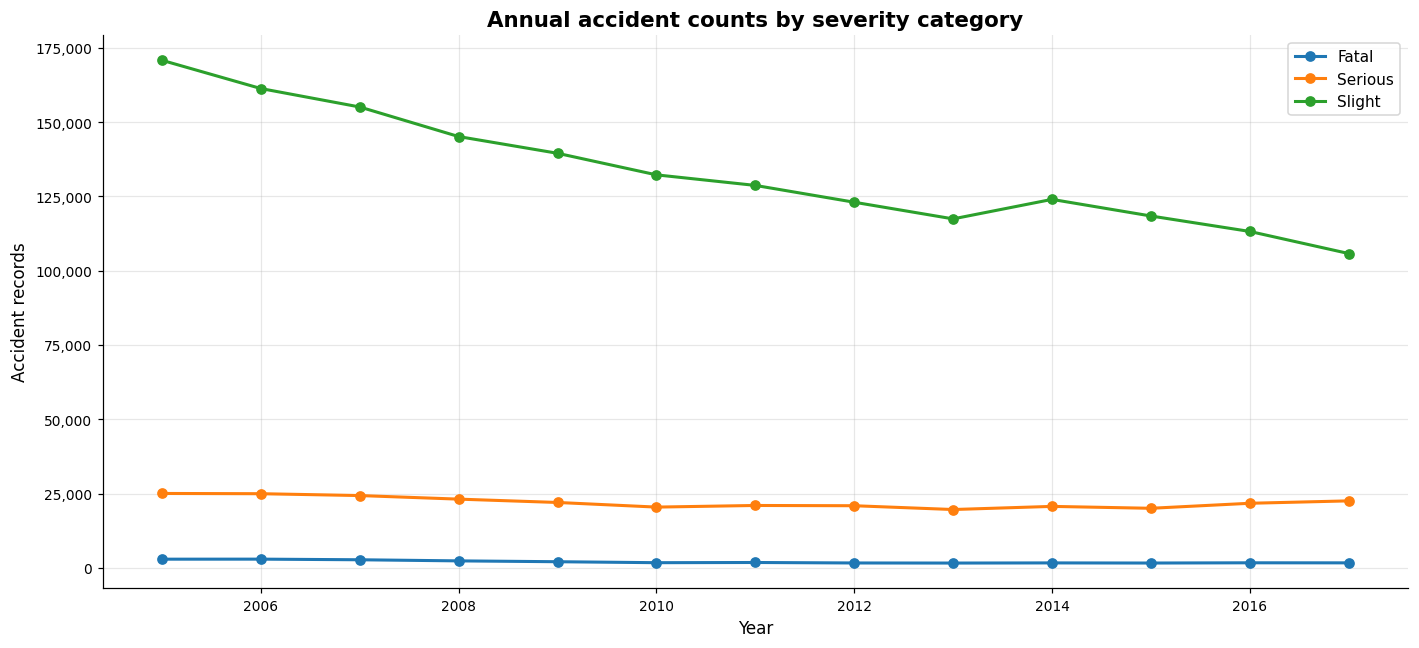

Interpretation: compare the direction and magnitude of each severity line. A decline in total accidents can coexist with a different pattern in fatal or serious accidents.


In [16]:
severity_year_pd = (
    accidents.filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Year", "Accident_Severity").count().orderBy("Year").toPandas()
)
severity_pivot = severity_year_pd.pivot(index="Year", columns="Accident_Severity", values="count").fillna(0)

fig, ax = plt.subplots(figsize=(13, 6))
for category in ["Fatal", "Serious", "Slight"]:
    if category in severity_pivot.columns:
        ax.plot(severity_pivot.index, severity_pivot[category], marker="o", linewidth=2, label=category)
ax.set_title("Annual accident counts by severity category")
ax.set_xlabel("Year"); ax.set_ylabel("Accident records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("Interpretation: compare the direction and magnitude of each severity line. A decline in total accidents can coexist with a different pattern in fatal or serious accidents.")

## 17. Monthly seasonality

**What this graph shows:** total accident records aggregated by calendar month across all years. It describes recurring seasonal concentration in the supplied records. It does not control for month length, weather exposure or traffic volume.

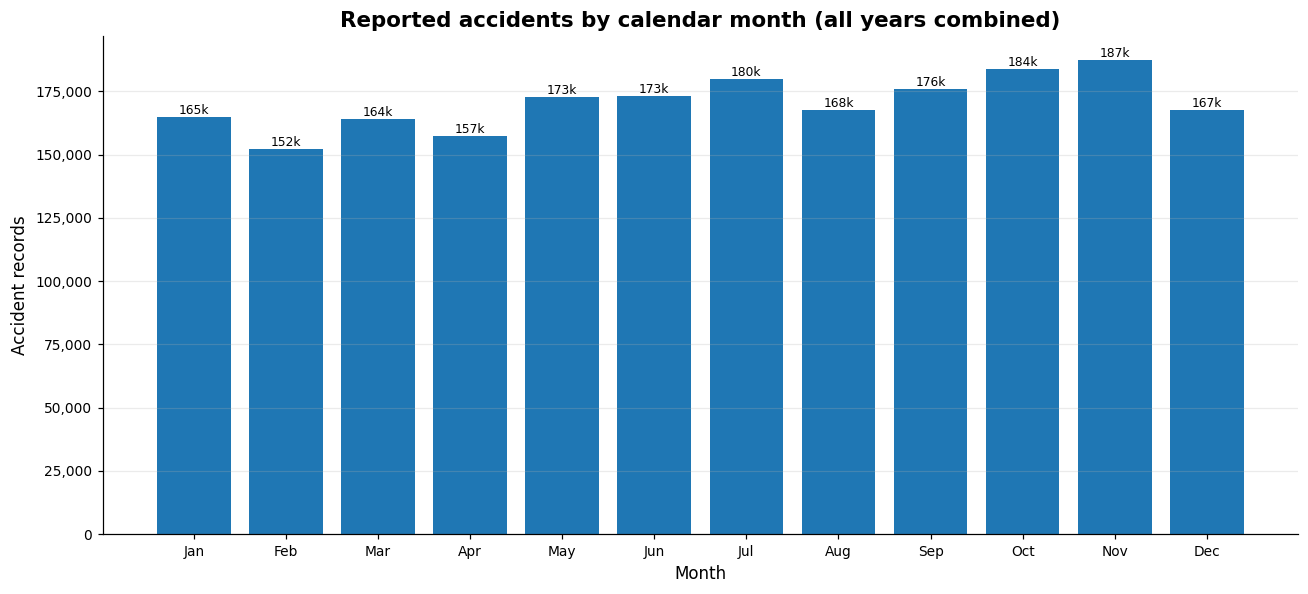

Interpretation: months with higher counts are periods with more records in this dataset. This is descriptive seasonality, not proof that a month is intrinsically more dangerous.


In [17]:
monthly_pd = accidents.filter(F.col("Month").isNotNull()).groupBy("Month").count().orderBy("Month").toPandas()
monthly_pd["Month_Name"] = monthly_pd["Month"].map(lambda x: calendar.month_abbr[int(x)])

fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(monthly_pd["Month_Name"], monthly_pd["count"])
for b, v in zip(bars, monthly_pd["count"]):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v/1000:.0f}k", ha="center", va="bottom", fontsize=8)
ax.set_title("Reported accidents by calendar month (all years combined)")
ax.set_xlabel("Month"); ax.set_ylabel("Accident records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="y")
plt.tight_layout(); plt.show()
print("Interpretation: months with higher counts are periods with more records in this dataset. This is descriptive seasonality, not proof that a month is intrinsically more dangerous.")

## 18. Accidents by day of week

**What this graph shows:** total accident counts by reported weekday. The weekdays are sorted in calendar order rather than alphabetically.

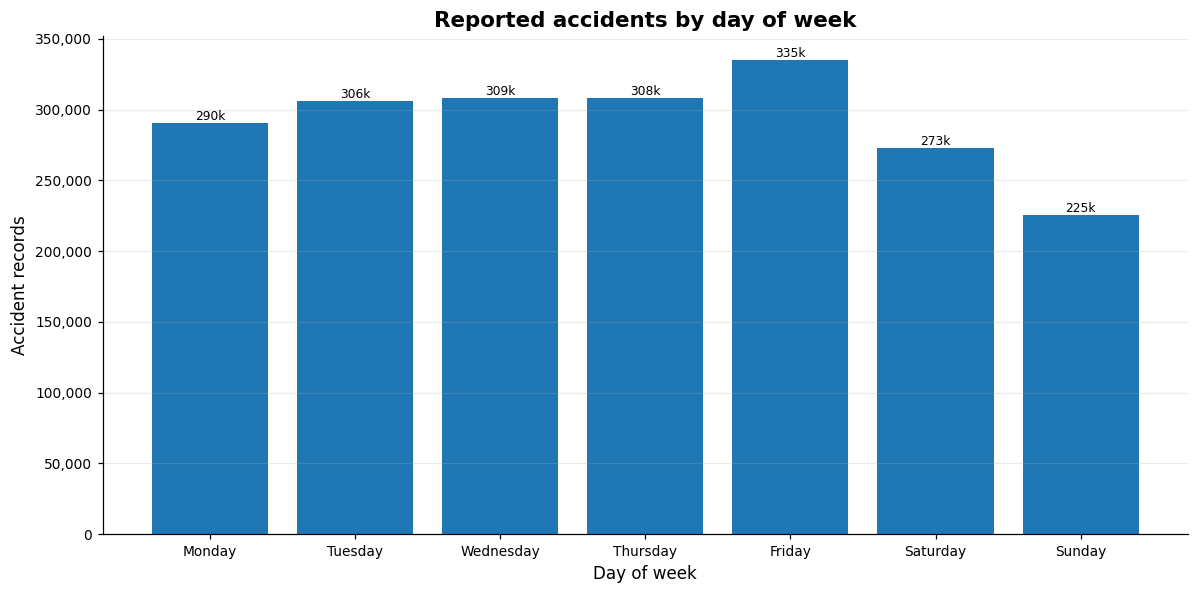

Interpretation: the graph highlights weekday/weekend differences in recorded accident volume. Traffic volume and trip purpose are not available as denominators here.


In [18]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_pd = accidents.groupBy("Day_of_Week").count().toPandas()
weekday_pd["Day_of_Week"] = pd.Categorical(weekday_pd["Day_of_Week"], categories=weekday_order, ordered=True)
weekday_pd = weekday_pd.sort_values("Day_of_Week")

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(weekday_pd["Day_of_Week"].astype(str), weekday_pd["count"])
for b, v in zip(bars, weekday_pd["count"]):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v/1000:.0f}k", ha="center", va="bottom", fontsize=8)
ax.set_title("Reported accidents by day of week")
ax.set_xlabel("Day of week"); ax.set_ylabel("Accident records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="y")
plt.tight_layout(); plt.show()
print("Interpretation: the graph highlights weekday/weekend differences in recorded accident volume. Traffic volume and trip purpose are not available as denominators here.")

## 19. Accidents by hour of day

**What this graph shows:** the number of accident records for each hour from 00:00 to 23:00. Invalid or unavailable time values are excluded from this chart.

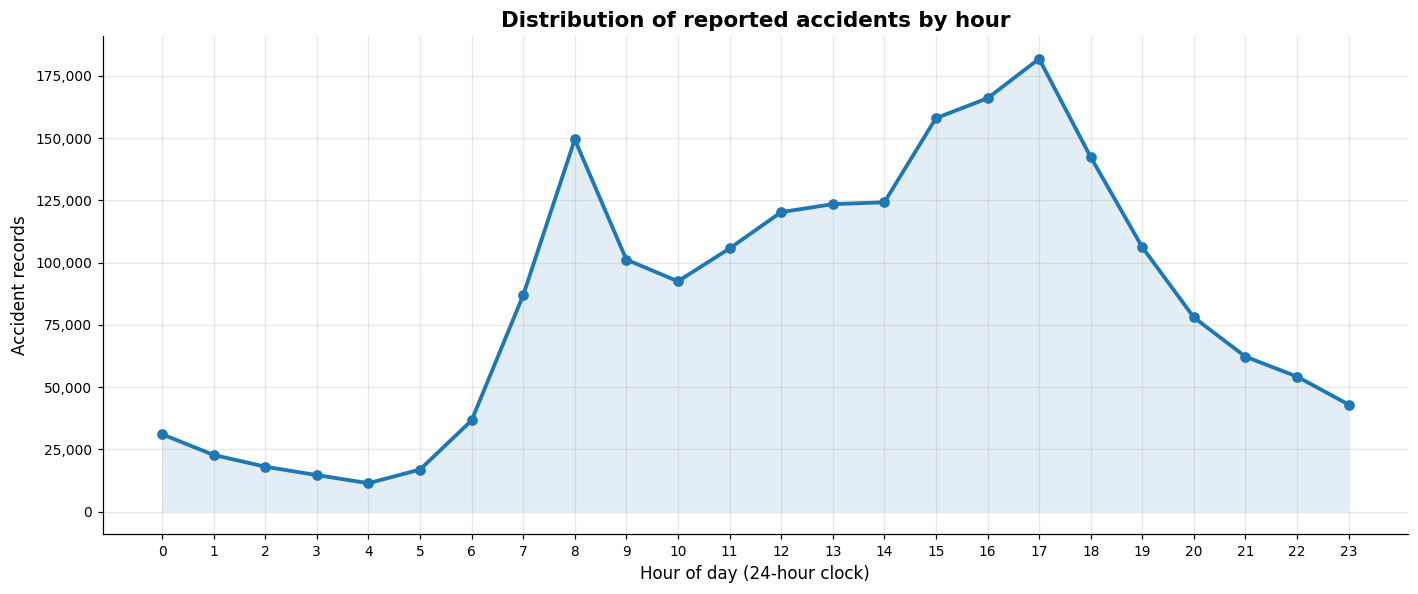

Interpretation: the highest recorded hour is 17:00 with 181,881 records. This does not adjust for the number of vehicles on the road at each hour.


In [19]:
hour_pd = accidents.filter(F.col("Hour").between(0, 23)).groupBy("Hour").count().orderBy("Hour").toPandas()
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(hour_pd["Hour"], hour_pd["count"], marker="o", linewidth=2.5)
ax.fill_between(hour_pd["Hour"], hour_pd["count"], alpha=.13)
ax.set_xticks(range(24)); ax.set_xlabel("Hour of day (24-hour clock)"); ax.set_ylabel("Accident records")
ax.set_title("Distribution of reported accidents by hour")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
peak_hour = hour_pd.loc[hour_pd["count"].idxmax()]
print(f"Interpretation: the highest recorded hour is {int(peak_hour['Hour']):02d}:00 with {int(peak_hour['count']):,} records. This does not adjust for the number of vehicles on the road at each hour.")

## 20. Weekday-by-hour accident heatmap

**What this graph shows:** accident counts for every combination of weekday and hour. It can reveal commuting-period concentration and whether weekend time patterns differ from weekday patterns.

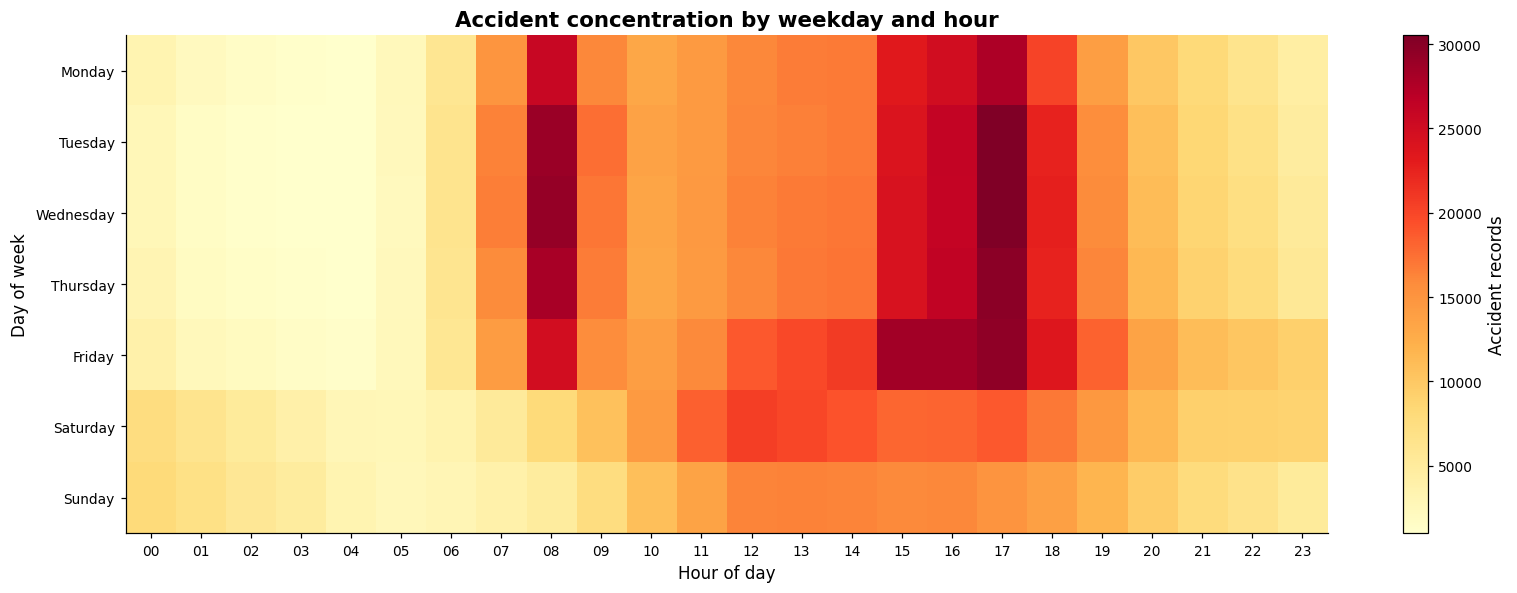

Interpretation: darker cells indicate time combinations with more recorded accidents. The heatmap describes observed volume, not per-driver risk.


In [20]:
weekday_hour_pd = (
    accidents.filter(F.col("Hour").between(0, 23))
    .groupBy("Day_of_Week", "Hour").count().toPandas()
)
heat = weekday_hour_pd.pivot(index="Day_of_Week", columns="Hour", values="count").reindex(weekday_order).fillna(0)

fig, ax = plt.subplots(figsize=(15, 5.5))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
ax.set_xticks(range(24)); ax.set_xticklabels([f"{h:02d}" for h in heat.columns])
ax.set_xlabel("Hour of day"); ax.set_ylabel("Day of week")
ax.set_title("Accident concentration by weekday and hour")
fig.colorbar(im, ax=ax, label="Accident records")
plt.tight_layout(); plt.show()
print("Interpretation: darker cells indicate time combinations with more recorded accidents. The heatmap describes observed volume, not per-driver risk.")

## 21. Weather conditions: accident volume

**What this graph shows:** accident counts for the most common recorded weather categories. Rare and unknown categories are excluded from this focused top-category display; their records are not deleted from the dataset.

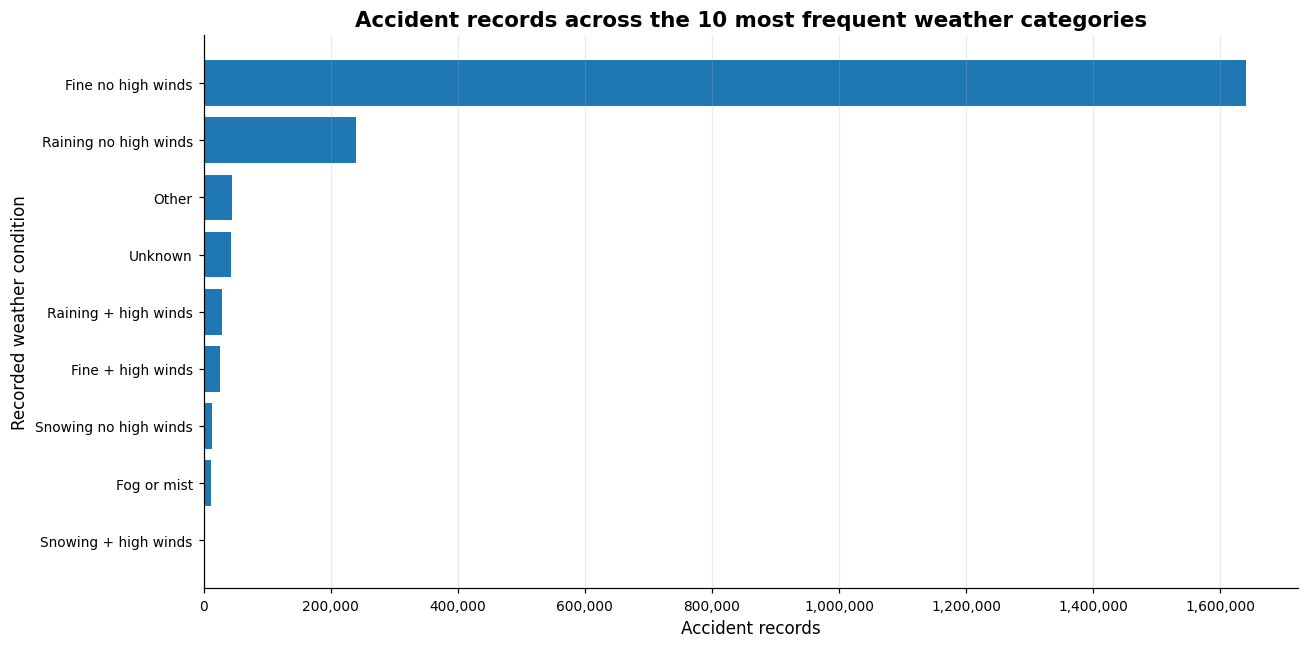

Interpretation: this chart shows where accident records are concentrated by reported weather. A high count in fine weather may reflect the amount of travel that occurs in fine weather; it is not evidence that fine weather is more hazardous.


In [21]:
weather_pd = (
    accidents.groupBy("Weather_Conditions").count()
    .orderBy(F.desc("count")).limit(10).toPandas()
    .sort_values("count")
)
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(weather_pd["Weather_Conditions"], weather_pd["count"])
ax.set_title("Accident records across the 10 most frequent weather categories")
ax.set_xlabel("Accident records"); ax.set_ylabel("Recorded weather condition")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: this chart shows where accident records are concentrated by reported weather. A high count in fine weather may reflect the amount of travel that occurs in fine weather; it is not evidence that fine weather is more hazardous.")

## 22. Severe-accident percentage by weather condition

**What this graph shows:** within each weather category, the percentage of known-severity accidents classified as Fatal or Serious. Categories with fewer than 1,000 records are excluded to avoid emphasizing very small groups. This remains an observational comparison.

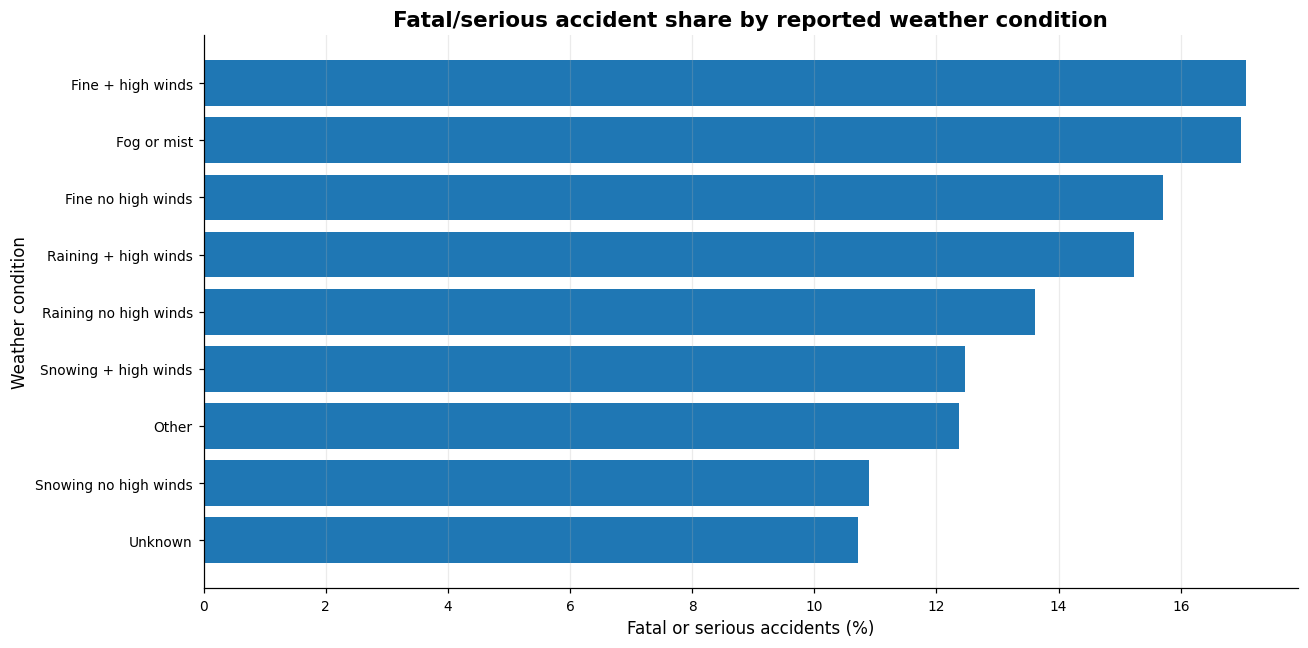

Interpretation: percentages compare severity composition within each weather group. They do not show causal weather effects; road use, speed, visibility and reporting may differ across groups.


In [22]:
weather_severity_pd = (
    accidents.filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Weather_Conditions")
    .agg(
        F.count("*").alias("Accidents"),
        F.sum("Is_Severe").alias("Severe_Accidents")
    )
    .filter(F.col("Accidents") >= 1000)
    .withColumn("Severe_Percent", 100 * F.col("Severe_Accidents") / F.col("Accidents"))
    .orderBy("Severe_Percent", ascending=False).toPandas()
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(weather_severity_pd["Weather_Conditions"], weather_severity_pd["Severe_Percent"])
ax.invert_yaxis()
ax.set_title("Fatal/serious accident share by reported weather condition")
ax.set_xlabel("Fatal or serious accidents (%)"); ax.set_ylabel("Weather condition")
ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: percentages compare severity composition within each weather group. They do not show causal weather effects; road use, speed, visibility and reporting may differ across groups.")

## 23. Road-surface conditions and severity composition

**What this graph shows:** the Fatal/Serious/Slight composition within each road-surface category. Each bar is normalized to 100%, allowing severity mix to be compared even when category counts differ. Groups with fewer than 1,000 records are omitted.

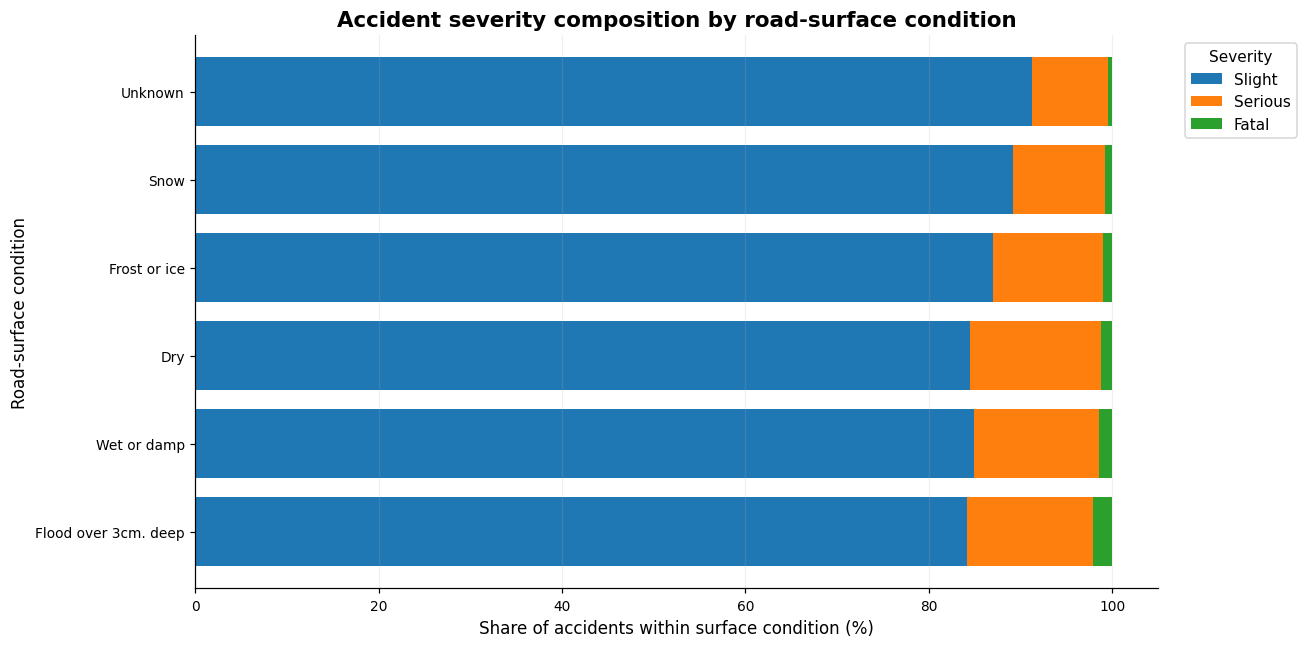

Interpretation: each bar sums to 100%. Compare the relative share of severe categories, not the absolute number of accidents. Unknown/not-applicable categories are retained only if they meet the volume threshold.


In [23]:
surface_severity = (
    accidents.filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Road_Surface_Conditions", "Accident_Severity").count().toPandas()
)
surface_total = surface_severity.groupby("Road_Surface_Conditions")["count"].sum()
valid_surfaces = surface_total[surface_total >= 1000].index
surface_severity = surface_severity[surface_severity["Road_Surface_Conditions"].isin(valid_surfaces)]
surface_pivot = surface_severity.pivot(index="Road_Surface_Conditions", columns="Accident_Severity", values="count").fillna(0)
surface_pct = surface_pivot.div(surface_pivot.sum(axis=1), axis=0) * 100
surface_pct = surface_pct.sort_values(by="Fatal", ascending=False) if "Fatal" in surface_pct else surface_pct

ax = surface_pct[[c for c in ["Slight", "Serious", "Fatal"] if c in surface_pct.columns]].plot(
    kind="barh", stacked=True, figsize=(12, 6), width=.78
)
ax.set_title("Accident severity composition by road-surface condition")
ax.set_xlabel("Share of accidents within surface condition (%)"); ax.set_ylabel("Road-surface condition")
ax.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()
print("Interpretation: each bar sums to 100%. Compare the relative share of severe categories, not the absolute number of accidents. Unknown/not-applicable categories are retained only if they meet the volume threshold.")

## 24. Light conditions and severe-accident percentage

**What this graph shows:** Fatal/Serious share within each light-condition group. This helps examine whether the severity mix differs between daylight, darkness with lighting and darkness without lighting. Only groups with at least 1,000 known-severity records are displayed.

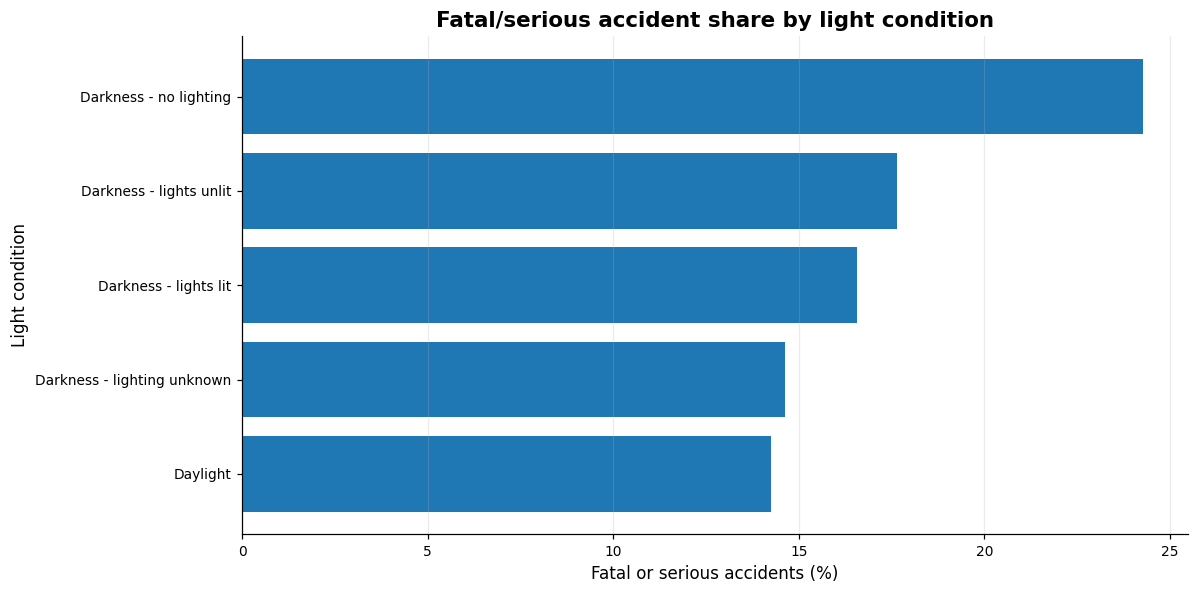

Interpretation: the percentage is conditional on recorded accidents in that lighting group. It is not an exposure-adjusted nighttime/daytime crash risk.


In [24]:
light_pd = (
    accidents.filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Light_Conditions")
    .agg(F.count("*").alias("N"), F.sum("Is_Severe").alias("Severe"))
    .filter(F.col("N") >= 1000)
    .withColumn("Severe_Percent", 100 * F.col("Severe") / F.col("N"))
    .orderBy("Severe_Percent", ascending=False).toPandas()
)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(light_pd["Light_Conditions"], light_pd["Severe_Percent"])
ax.invert_yaxis(); ax.set_title("Fatal/serious accident share by light condition")
ax.set_xlabel("Fatal or serious accidents (%)"); ax.set_ylabel("Light condition")
ax.grid(axis="x"); plt.tight_layout(); plt.show()
print("Interpretation: the percentage is conditional on recorded accidents in that lighting group. It is not an exposure-adjusted nighttime/daytime crash risk.")

## 25. Accident volume by road type

**What this graph shows:** the most frequently recorded road types in the accident file. This highlights where the dataset records the largest volumes of collisions, but does not adjust for kilometres travelled or road length.

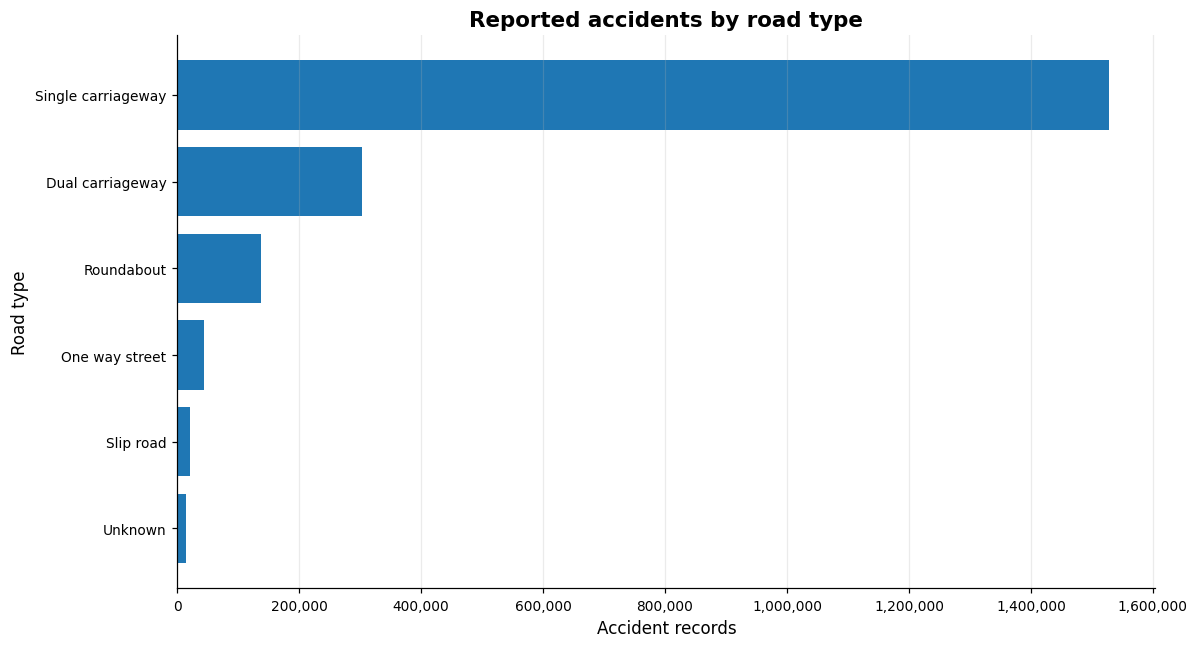

Interpretation: a higher count can reflect more traffic or more road kilometres of that type. It should not be interpreted as a per-kilometre or per-trip risk comparison.


In [25]:
road_type_pd = accidents.groupBy("Road_Type").count().orderBy(F.desc("count")).limit(12).toPandas().sort_values("count")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(road_type_pd["Road_Type"], road_type_pd["count"])
ax.set_title("Reported accidents by road type")
ax.set_xlabel("Accident records"); ax.set_ylabel("Road type")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: a higher count can reflect more traffic or more road kilometres of that type. It should not be interpreted as a per-kilometre or per-trip risk comparison.")

## 26. Accident distribution by speed limit

**What this graph shows:** accident counts across the recorded speed-limit categories. The chart uses the speed-limit field as recorded in the collision data; it is not the actual speed of the vehicle at the time of the collision.

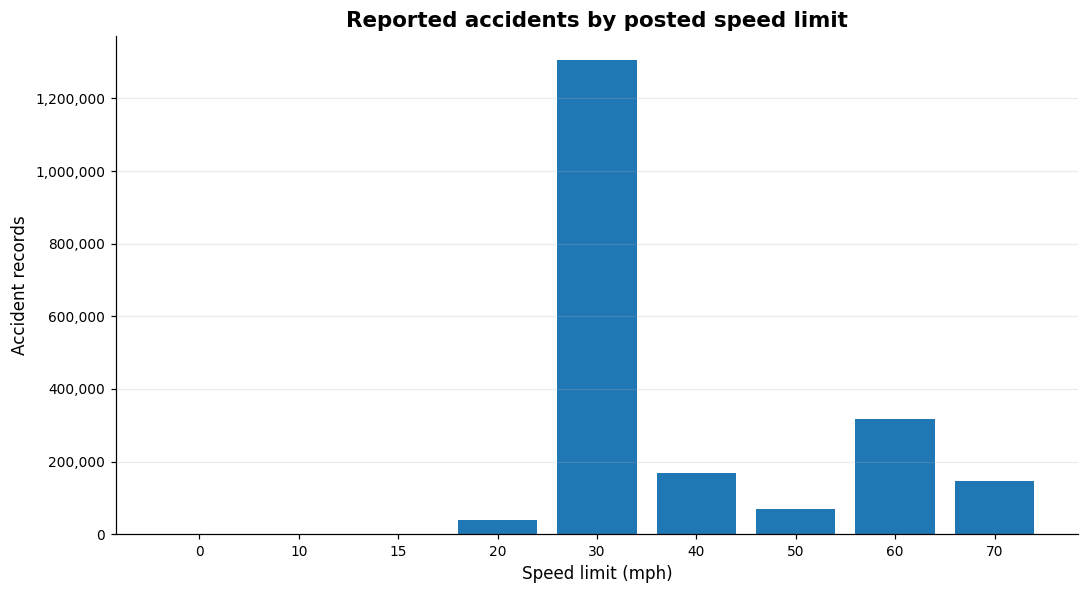

Interpretation: this shows the distribution of recorded accident locations by posted speed limit. It does not measure the speed driven by the people involved.


In [26]:
speed_pd = (
    accidents.filter(F.col("Speed_limit").isNotNull())
    .groupBy("Speed_limit").count().orderBy("Speed_limit").toPandas()
)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(speed_pd["Speed_limit"].astype(int).astype(str), speed_pd["count"])
ax.set_title("Reported accidents by posted speed limit")
ax.set_xlabel("Speed limit (mph)"); ax.set_ylabel("Accident records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="y")
plt.tight_layout(); plt.show()
print("Interpretation: this shows the distribution of recorded accident locations by posted speed limit. It does not measure the speed driven by the people involved.")

## 27. Severe-accident percentage by speed limit

**What this graph shows:** the percentage of Fatal/Serious accidents among all accidents recorded at each posted speed limit. This is a severity-composition comparison and does not establish that the speed limit caused a severity outcome.

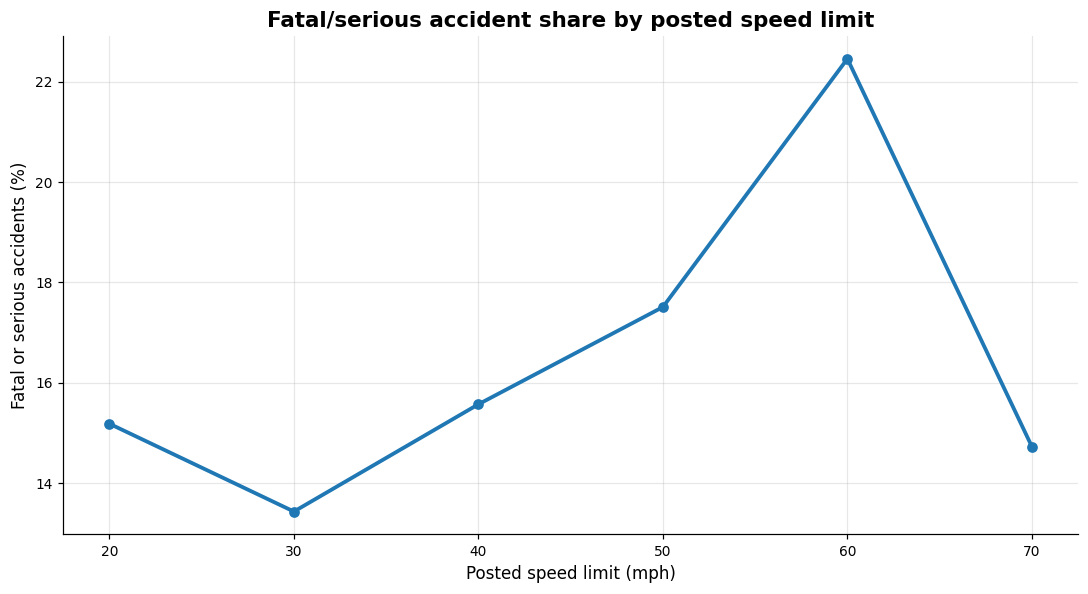

Interpretation: each point is a severity share among recorded accidents at that speed limit. Differences may reflect road design, land use, traffic mix and other confounders.


In [27]:
speed_severity_pd = (
    accidents.filter(F.col("Speed_limit").isNotNull() & F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Speed_limit")
    .agg(F.count("*").alias("N"), F.sum("Is_Severe").alias("Severe"))
    .filter(F.col("N") >= 500)
    .withColumn("Severe_Percent", 100 * F.col("Severe") / F.col("N"))
    .orderBy("Speed_limit").toPandas()
)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(speed_severity_pd["Speed_limit"], speed_severity_pd["Severe_Percent"], marker="o", linewidth=2.5)
ax.set_title("Fatal/serious accident share by posted speed limit")
ax.set_xlabel("Posted speed limit (mph)"); ax.set_ylabel("Fatal or serious accidents (%)")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("Interpretation: each point is a severity share among recorded accidents at that speed limit. Differences may reflect road design, land use, traffic mix and other confounders.")

## 28. Urban versus rural accident severity

**What this graph shows:** the severity composition within Urban, Rural and any other recorded area category. Each area is normalized to 100%. The chart compares severity mix rather than raw totals.

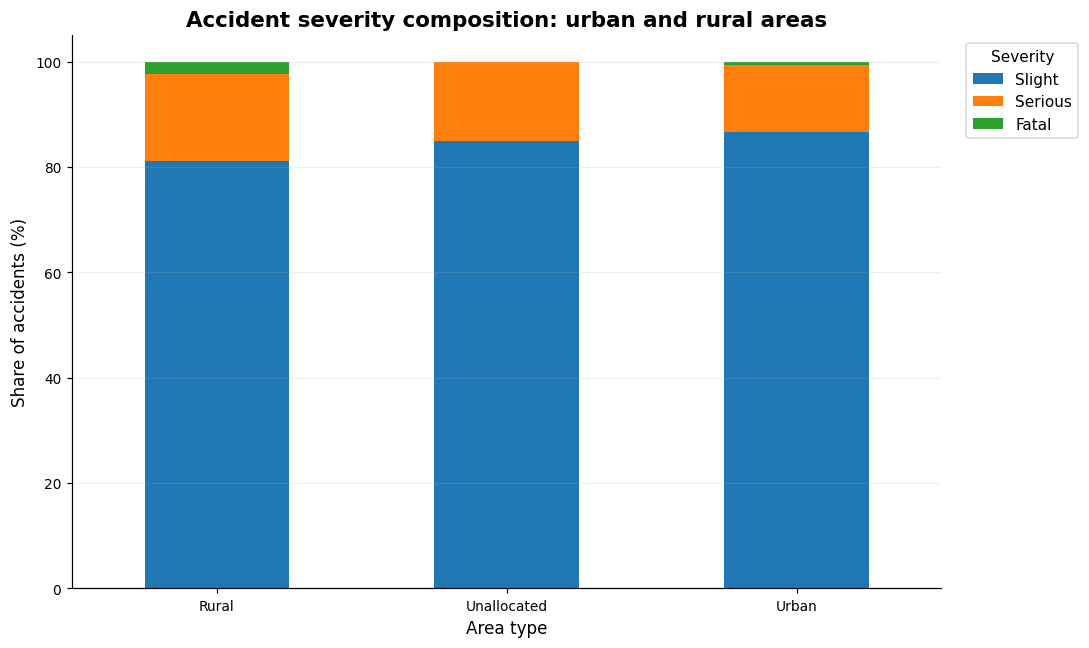

Interpretation: compare the within-area proportions of fatal, serious and slight accidents. This is not a rate per resident, road kilometre or vehicle journey.


In [28]:
area_severity_pd = (
    accidents.filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Urban_or_Rural_Area", "Accident_Severity").count().toPandas()
)
area_pivot = area_severity_pd.pivot(index="Urban_or_Rural_Area", columns="Accident_Severity", values="count").fillna(0)
area_pct = area_pivot.div(area_pivot.sum(axis=1), axis=0) * 100
ax = area_pct[[c for c in ["Slight", "Serious", "Fatal"] if c in area_pct.columns]].plot(kind="bar", stacked=True, figsize=(10, 6))
ax.set_title("Accident severity composition: urban and rural areas")
ax.set_xlabel("Area type"); ax.set_ylabel("Share of accidents (%)")
ax.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=.2); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Interpretation: compare the within-area proportions of fatal, serious and slight accidents. This is not a rate per resident, road kilometre or vehicle journey.")

## 29. Annual casualty trend

**What this graph shows:** the total number of casualties recorded in accidents each year. This is a casualty count, not the number of accidents; one accident can have multiple casualties.

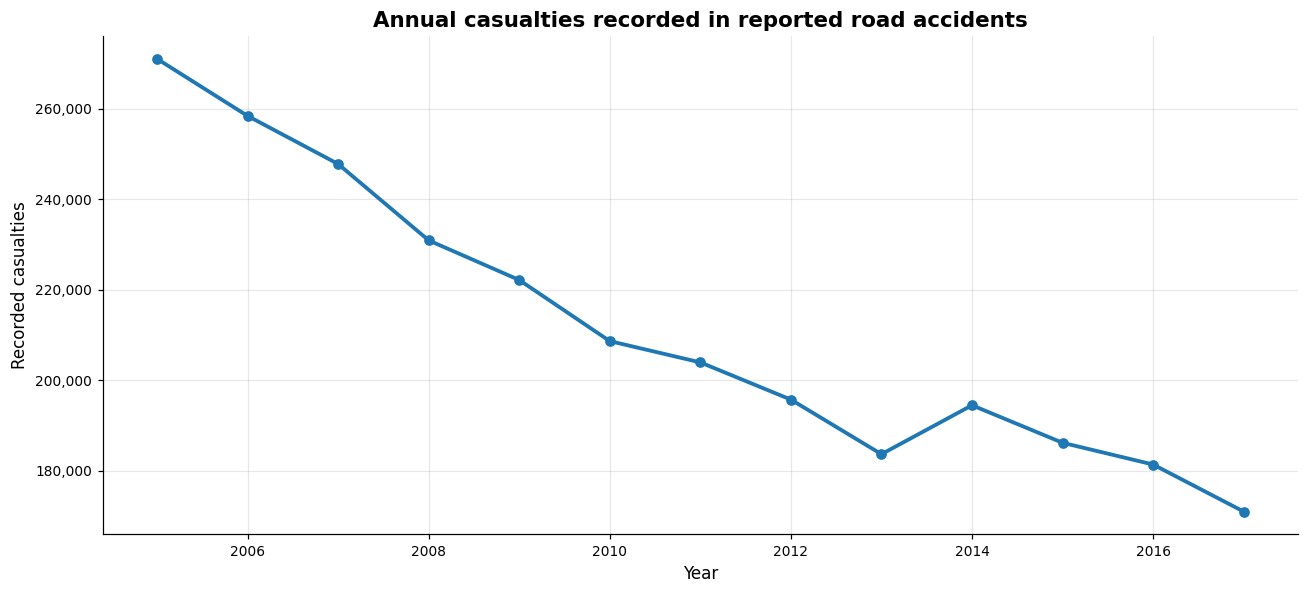

Interpretation: this tracks the human-impact volume recorded each year. Compare it with annual accident counts to understand whether average casualties per accident changed.


In [29]:
casualty_year_pd = (
    accidents.groupBy("Year")
    .agg(F.sum("Number_of_Casualties").alias("Casualties"))
    .orderBy("Year").toPandas()
)
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(casualty_year_pd["Year"], casualty_year_pd["Casualties"], marker="o", linewidth=2.5)
ax.set_title("Annual casualties recorded in reported road accidents")
ax.set_xlabel("Year"); ax.set_ylabel("Recorded casualties")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Interpretation: this tracks the human-impact volume recorded each year. Compare it with annual accident counts to understand whether average casualties per accident changed.")

## 30. Casualties per accident distribution

**What this graph shows:** the distribution of casualty counts per accident. The histogram is capped at the 99th percentile for readability; the excluded extreme tail is reported separately in the text.

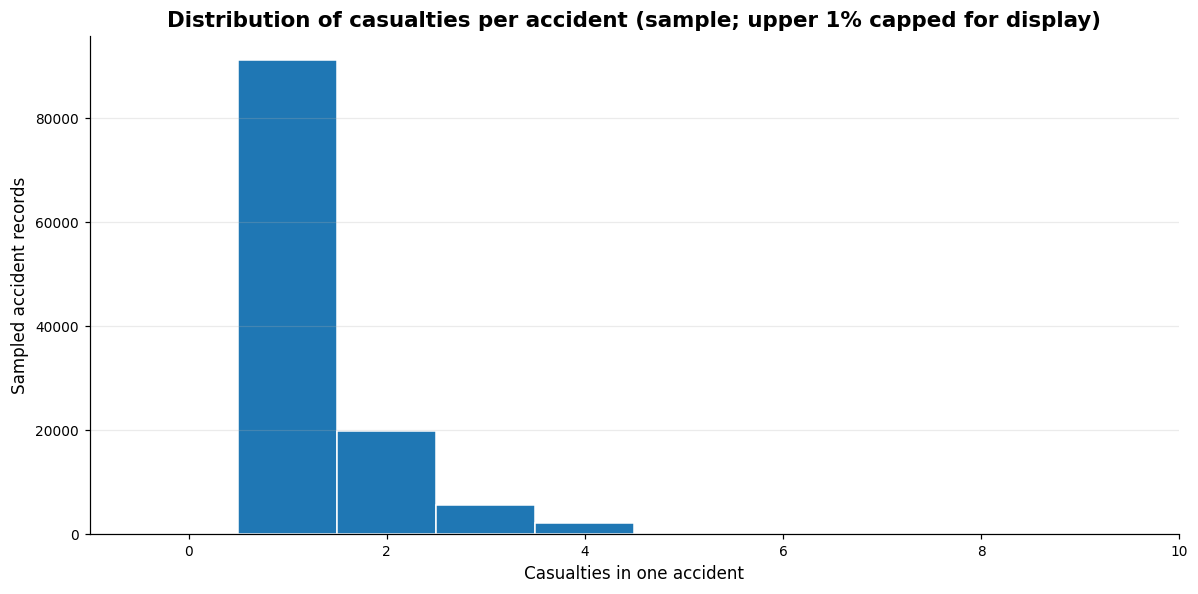

Interpretation: the 99th percentile of this sample is 4 casualties per accident. The histogram focuses on the main distribution; rare high-casualty events remain part of the underlying data.


In [30]:
casualty_sample = (
    accidents.filter(F.col("Number_of_Casualties").isNotNull() & (F.col("Number_of_Casualties") >= 0))
    .select("Number_of_Casualties").sample(False, 0.12, seed=42).limit(120000).toPandas()
)
cap = float(casualty_sample["Number_of_Casualties"].quantile(.99))
plot_values = casualty_sample.loc[casualty_sample["Number_of_Casualties"] <= cap, "Number_of_Casualties"]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(plot_values, bins=np.arange(-.5, max(10, int(cap)+1.5), 1), edgecolor="white")
ax.set_title("Distribution of casualties per accident (sample; upper 1% capped for display)")
ax.set_xlabel("Casualties in one accident"); ax.set_ylabel("Sampled accident records")
ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()
print(f"Interpretation: the 99th percentile of this sample is {cap:.0f} casualties per accident. The histogram focuses on the main distribution; rare high-casualty events remain part of the underlying data.")

## 31. Local-authority districts with the most recorded accidents

**What this graph shows:** the 15 local-authority districts with the highest counts. It identifies where the dataset contains the greatest collision volume. Counts are not normalized for district population, road length or traffic.

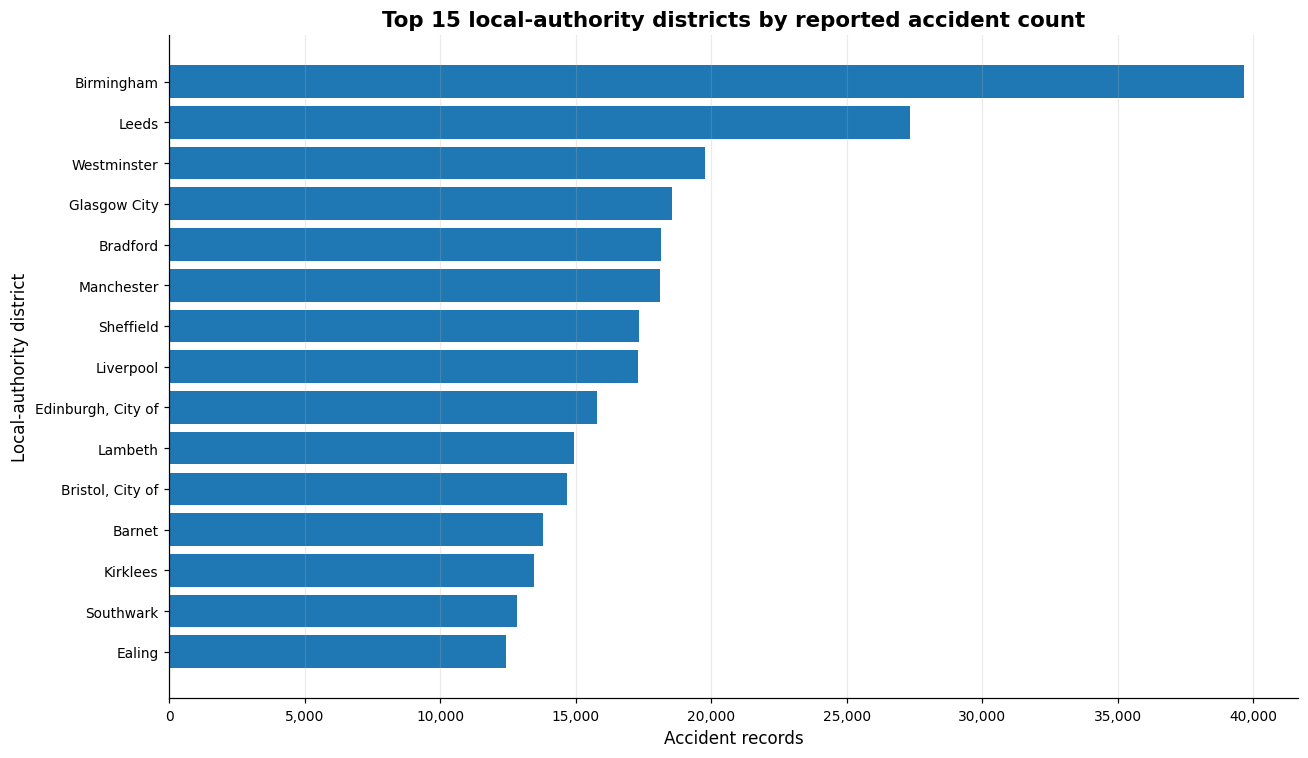

Interpretation: high-volume districts may have larger populations, denser roads or more traffic. Treat this as a count-based hotspot ranking, not a risk ranking.


In [31]:
district_col = F.col("`Local_Authority_(District)`")
district_pd = (
    accidents.groupBy(district_col.alias("District"))
    .count().orderBy(F.desc("count")).limit(15).toPandas()
    .sort_values("count")
)
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(district_pd["District"], district_pd["count"])
ax.set_title("Top 15 local-authority districts by reported accident count")
ax.set_xlabel("Accident records"); ax.set_ylabel("Local-authority district")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: high-volume districts may have larger populations, denser roads or more traffic. Treat this as a count-based hotspot ranking, not a risk ranking.")

## 32. Geographic accident-density map

**What this map shows:** a sampled heatmap of accident coordinates across Great Britain. The map is based on valid latitude/longitude pairs and is capped at 40,000 sampled points to keep the notebook responsive. It is a visual density aid, not a statistically adjusted hotspot model.

In [51]:

# ============================================================
# UK ROAD ACCIDENT HOTSPOT MAP
# CARTO POSITRON BASEMAP WITH API AUTHENTICATION
# ============================================================

!pip -q install folium

import folium
import pandas as pd
from folium.plugins import HeatMap
from pyspark.sql import functions as F
from getpass import getpass
from urllib.parse import quote
from IPython.display import display

# ------------------------------------------------------------
# 1. CARTO API KEY
# ------------------------------------------------------------

CARTO_API_KEY = getpass("Enter your CARTO Basemaps API Key: ").strip()

if not CARTO_API_KEY:
    raise ValueError("CARTO API key is required.")

CARTO_API_KEY = quote(CARTO_API_KEY, safe="")

# ------------------------------------------------------------
# 2. PREPARE GEOGRAPHICAL DATA
# ------------------------------------------------------------

geo_sample = (
    accidents
    .select(
        F.col("Latitude").cast("double").alias("Latitude"),
        F.col("Longitude").cast("double").alias("Longitude")
    )
    .filter(
        F.col("Latitude").between(49.5, 59.5) &
        F.col("Longitude").between(-8.5, 2.2)
    )
    .dropna()
    .sample(
        withReplacement=False,
        fraction=0.04,
        seed=27
    )
    .limit(40000)
    .toPandas()
)

if geo_sample.empty:
    raise ValueError("No valid accident coordinates available.")

print(f"Valid coordinates selected: {len(geo_sample):,}")

# ------------------------------------------------------------
# 3. INITIALIZE MAP
# ------------------------------------------------------------

accident_map = folium.Map(
    location=[54.5, -2.5],
    zoom_start=5,
    tiles=None,
    control_scale=True,
    width="100%",
    height=600
)

# ------------------------------------------------------------
# 4. ADD AUTHENTICATED CARTO POSITRON BASEMAP
# ------------------------------------------------------------

carto_tiles = (
    "https://{s}.basemaps.cartocdn.com/"
    "rastertiles/light_all/{z}/{x}/{y}.png"
    f"?key={CARTO_API_KEY}"
)

folium.TileLayer(
    tiles=carto_tiles,
    attr=(
        '&copy; <a href="https://www.openstreetmap.org/copyright">'
        'OpenStreetMap contributors</a> '
        '&copy; <a href="https://carto.com/attributions/">CARTO</a>'
    ),
    name="CARTO Positron",
    subdomains="abcd",
    max_zoom=20,
    overlay=False,
    control=True
).add_to(accident_map)

# ------------------------------------------------------------
# 5. ADD ACCIDENT DENSITY HEATMAP
# ------------------------------------------------------------

heat_data = geo_sample[
    ["Latitude", "Longitude"]
].values.tolist()

HeatMap(
    heat_data,
    radius=8,
    blur=10,
    min_opacity=0.25,
    max_zoom=12,
    name="Accident Density"
).add_to(accident_map)

# ------------------------------------------------------------
# 6. MAP CONTROLS
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(accident_map)

# ------------------------------------------------------------
# 7. DISPLAY MAP
# ------------------------------------------------------------

display(accident_map)

# ------------------------------------------------------------
# 8. ANALYTICAL INTERPRETATION
# ------------------------------------------------------------

print("\nGEOGRAPHICAL ANALYSIS")

print(f"Mapped coordinate pairs: {len(geo_sample):,}")
print("Geographical coverage: United Kingdom")
print("Basemap: CARTO Positron")
print("Visualization: Accident Density Heatmap")

print(
    "\nInterpretation: Areas with stronger heatmap intensity "
    "contain higher concentrations of recorded accident "
    "locations within the sampled dataset. This represents "
    "recorded accident density, not population-adjusted "
    "or traffic-exposure-adjusted accident risk."
)


Enter your CARTO Basemaps API Key: ··········
Valid coordinates selected: 40,000



GEOGRAPHICAL ANALYSIS
Mapped coordinate pairs: 40,000
Geographical coverage: United Kingdom
Basemap: CARTO Positron
Visualization: Accident Density Heatmap

Interpretation: Areas with stronger heatmap intensity contain higher concentrations of recorded accident locations within the sampled dataset. This represents recorded accident density, not population-adjusted or traffic-exposure-adjusted accident risk.


## 33. Vehicle types involved in reported accidents

**What this graph shows:** the most common vehicle categories in the vehicle-level file. A vehicle involvement is counted once per vehicle record, so multi-vehicle collisions contribute more than one vehicle row.

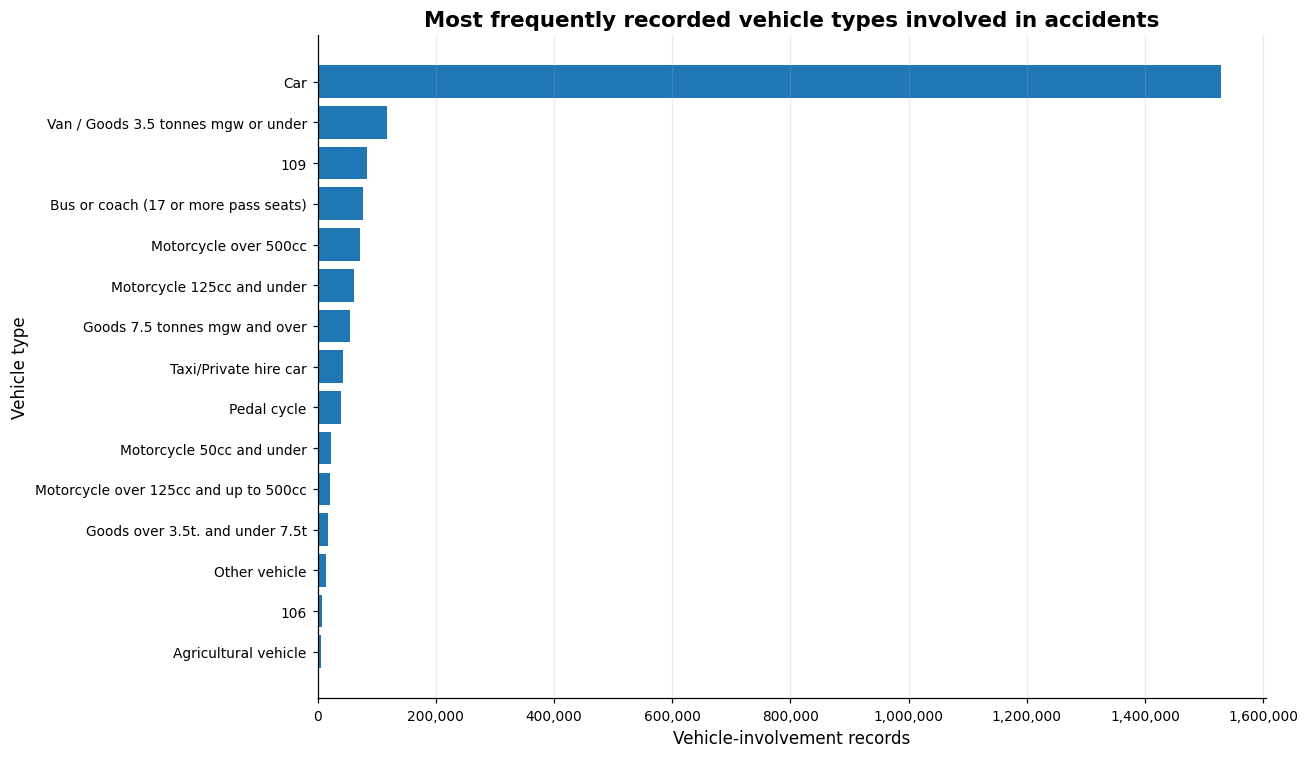

Interpretation: these are vehicle involvements in reported collisions, not accident totals by vehicle type and not per-vehicle risk. Vehicle fleet exposure is not supplied as a denominator.


In [33]:
vehicle_type_col = F.col("Vehicle_Type")
vehicle_type_pd = (
    vehicles.filter(~vehicle_type_col.isin("Unknown", "NA"))
    .groupBy("Vehicle_Type").count().orderBy(F.desc("count")).limit(15).toPandas()
    .sort_values("count")
)
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(vehicle_type_pd["Vehicle_Type"], vehicle_type_pd["count"])
ax.set_title("Most frequently recorded vehicle types involved in accidents")
ax.set_xlabel("Vehicle-involvement records"); ax.set_ylabel("Vehicle type")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: these are vehicle involvements in reported collisions, not accident totals by vehicle type and not per-vehicle risk. Vehicle fleet exposure is not supplied as a denominator.")

## 34. Driver age-band distribution

**What this graph shows:** vehicle-involvement records by the driver's recorded age band. It describes drivers associated with vehicles in reported collisions; it is not a comparison of risk per licensed driver or per mile travelled.

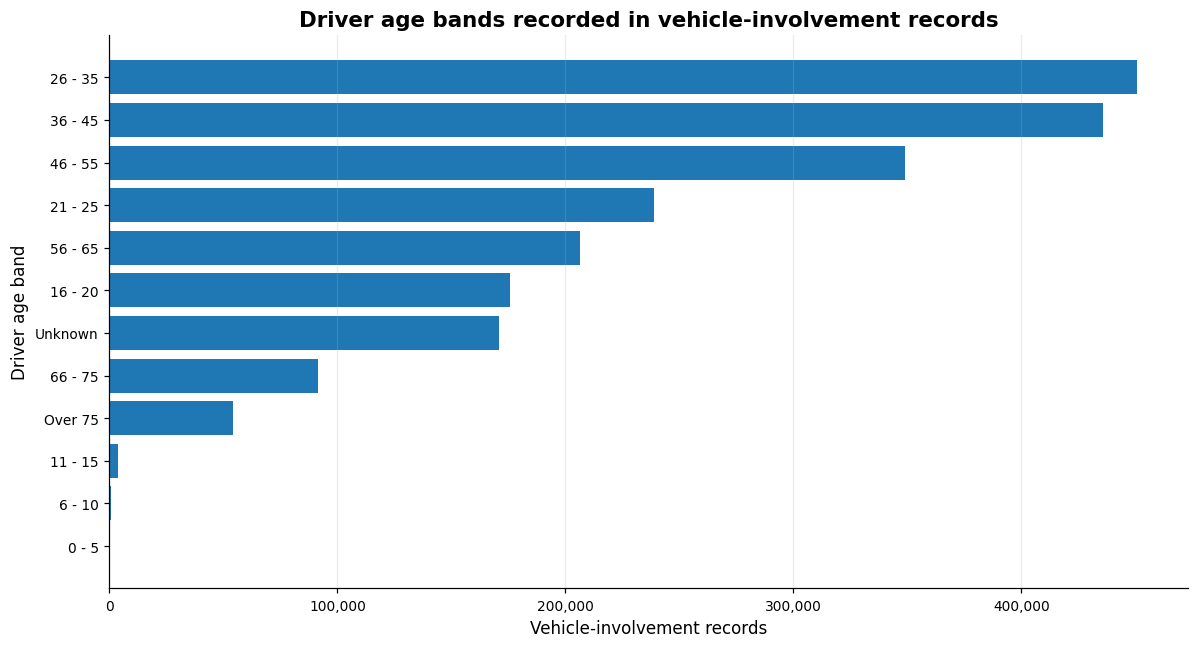

Interpretation: the plot shows the distribution of recorded driver age bands among accident-involved vehicles. A high count does not imply higher individual risk without age-specific exposure data.


In [34]:
age_order = ["Data missing or out of range", "Unknown", "0 - 5", "6 - 10", "11 - 15", "16 - 20", "21 - 25", "26 - 35", "36 - 45", "46 - 55", "56 - 65", "66 - 75", "Over 75"]
age_pd = vehicles.groupBy("Age_Band_of_Driver").count().orderBy("Age_Band_of_Driver").toPandas()
age_pd = age_pd.sort_values("count")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(age_pd["Age_Band_of_Driver"], age_pd["count"])
ax.set_title("Driver age bands recorded in vehicle-involvement records")
ax.set_xlabel("Vehicle-involvement records"); ax.set_ylabel("Driver age band")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: the plot shows the distribution of recorded driver age bands among accident-involved vehicles. A high count does not imply higher individual risk without age-specific exposure data.")

## 35. Driver sex distribution

**What this graph shows:** counts of vehicle-involvement records by recorded driver sex. Unavailable or not-known categories are shown separately where present.

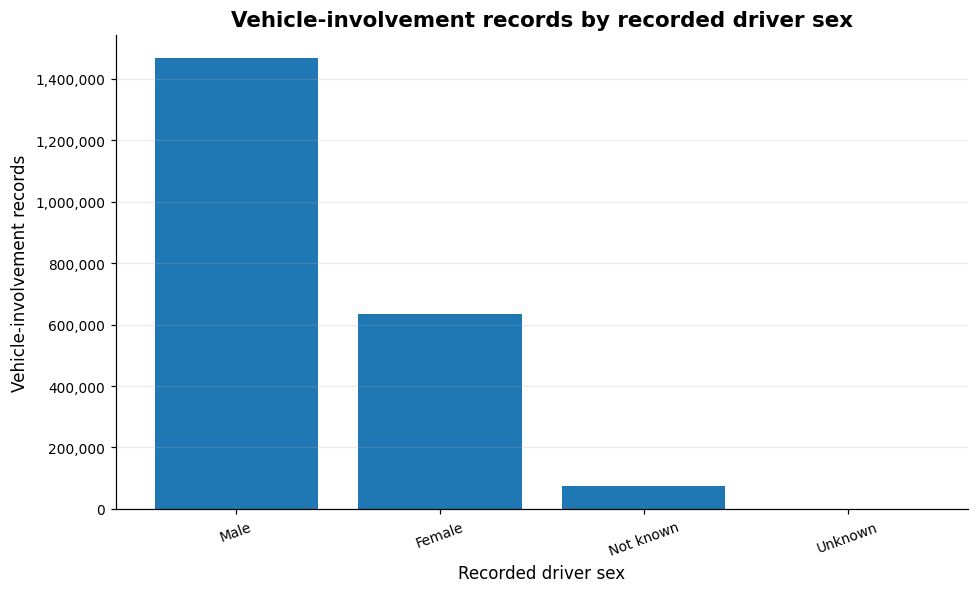

Interpretation: this compares the records in the vehicle file. It must not be interpreted as a male/female driver risk comparison because exposure by driver sex is not available.


In [35]:
sex_pd = vehicles.groupBy("Sex_of_Driver").count().orderBy(F.desc("count")).toPandas()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(sex_pd["Sex_of_Driver"].astype(str), sex_pd["count"])
ax.set_title("Vehicle-involvement records by recorded driver sex")
ax.set_xlabel("Recorded driver sex"); ax.set_ylabel("Vehicle-involvement records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="y")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print("Interpretation: this compares the records in the vehicle file. It must not be interpreted as a male/female driver risk comparison because exposure by driver sex is not available.")

## 36. Vehicle age distribution

**What this graph shows:** the distribution of recorded vehicle age in years. Invalid and unavailable numeric values are excluded; the chart is capped at 40 years for display clarity.

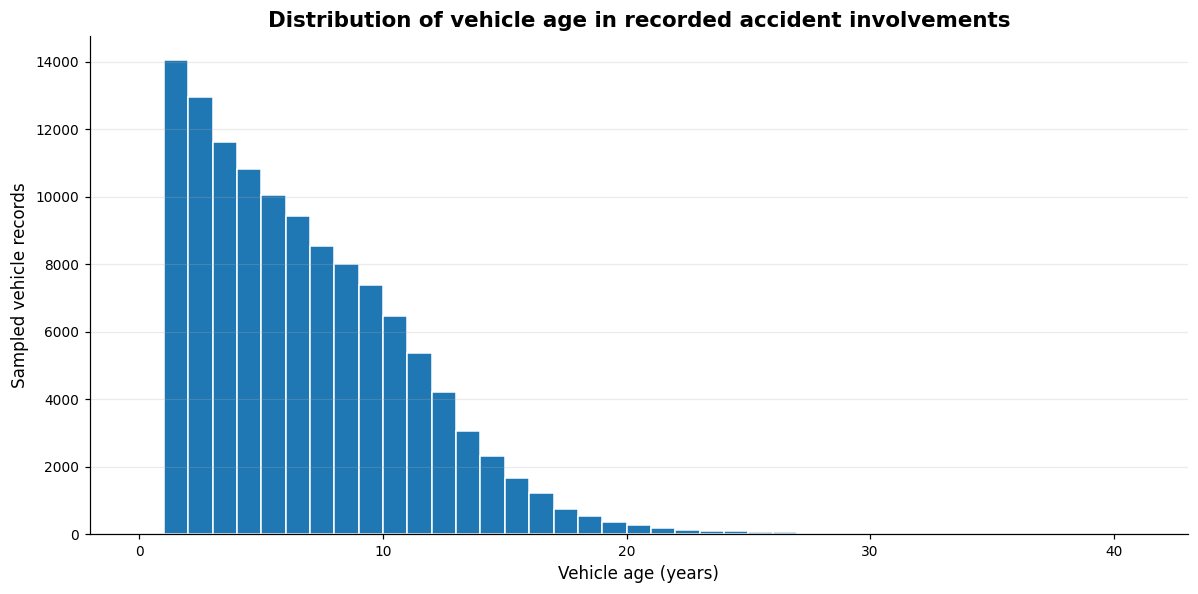

Interpretation: this describes the age profile of vehicles appearing in the accident file. It is not a failure rate by vehicle age because the number of vehicles of each age on the road is unknown.


In [36]:
vehicle_age_sample = (
    vehicles.filter(F.col("Age_of_Vehicle").between(0, 100))
    .select("Age_of_Vehicle").sample(False, .15, seed=19).limit(120000).toPandas()
)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(vehicle_age_sample["Age_of_Vehicle"], bins=np.arange(0, 42, 1), edgecolor="white")
ax.set_title("Distribution of vehicle age in recorded accident involvements")
ax.set_xlabel("Vehicle age (years)"); ax.set_ylabel("Sampled vehicle records")
ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()
print("Interpretation: this describes the age profile of vehicles appearing in the accident file. It is not a failure rate by vehicle age because the number of vehicles of each age on the road is unknown.")

## 37. Vehicle propulsion / fuel category

**What this graph shows:** the most frequently recorded propulsion categories among vehicle involvements. This field may have more missing or not-applicable values in older years, so results should be read with the dataset's time coverage in mind.

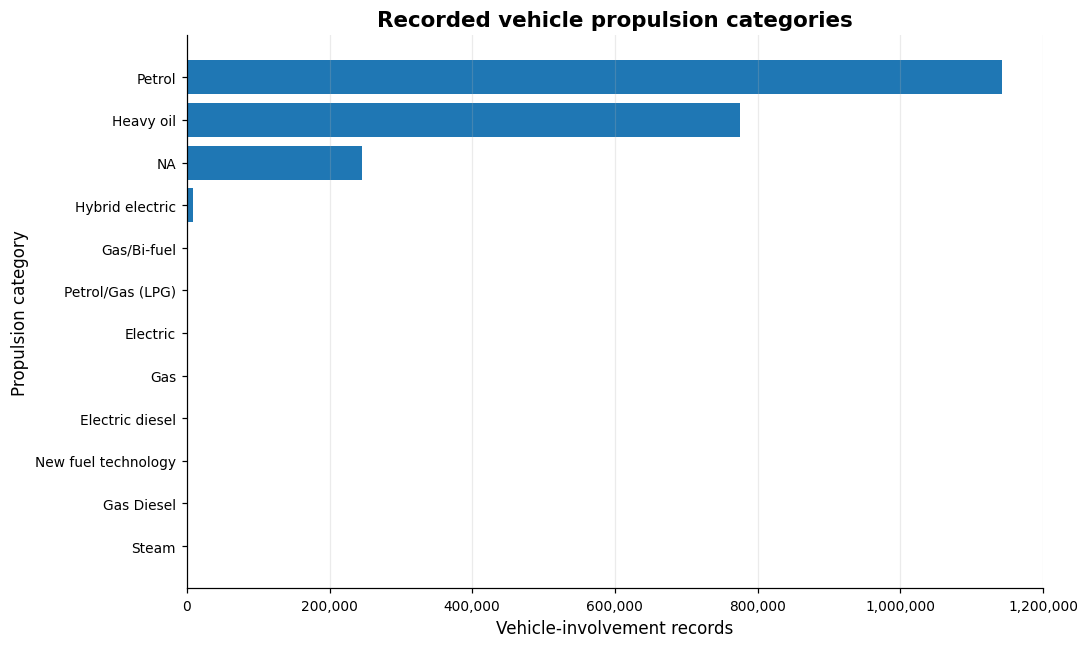

Interpretation: category counts indicate how frequently propulsion types appear in the source records, not their accident risk or fleet share.


In [37]:
prop_pd = (
    vehicles.groupBy("Propulsion_Code").count()
    .orderBy(F.desc("count")).limit(12).toPandas().sort_values("count")
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(prop_pd["Propulsion_Code"], prop_pd["count"])
ax.set_title("Recorded vehicle propulsion categories")
ax.set_xlabel("Vehicle-involvement records"); ax.set_ylabel("Propulsion category")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: category counts indicate how frequently propulsion types appear in the source records, not their accident risk or fleet share.")

## 38. Vehicle manoeuvres recorded before collision

**What this graph shows:** the most common recorded manoeuvres for vehicles involved in accidents. It helps describe the driving situations represented in the dataset.

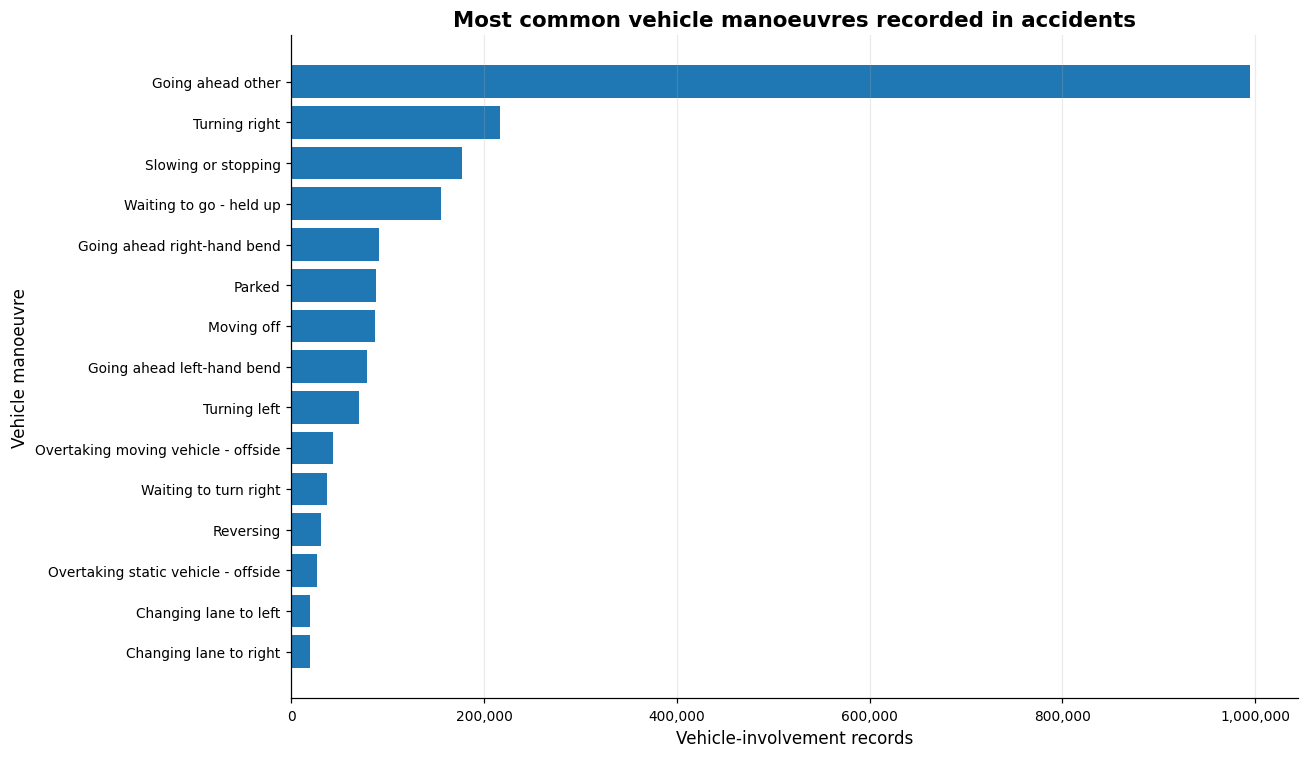

Interpretation: this graph describes manoeuvres associated with accident-involved vehicles. It does not estimate the risk of a manoeuvre without knowing how often that manoeuvre occurs in normal driving.


In [38]:
manoeuvre_pd = (
    vehicles.groupBy("Vehicle_Manoeuvre").count()
    .orderBy(F.desc("count")).limit(15).toPandas().sort_values("count")
)
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(manoeuvre_pd["Vehicle_Manoeuvre"], manoeuvre_pd["count"])
ax.set_title("Most common vehicle manoeuvres recorded in accidents")
ax.set_xlabel("Vehicle-involvement records"); ax.set_ylabel("Vehicle manoeuvre")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: this graph describes manoeuvres associated with accident-involved vehicles. It does not estimate the risk of a manoeuvre without knowing how often that manoeuvre occurs in normal driving.")

## 39. Driver journey purpose

**What this graph shows:** vehicle-involvement counts across the recorded journey-purpose categories. This can highlight whether accidents in the file are more frequently associated with commuting, business, leisure or other journey purposes where these categories are recorded.

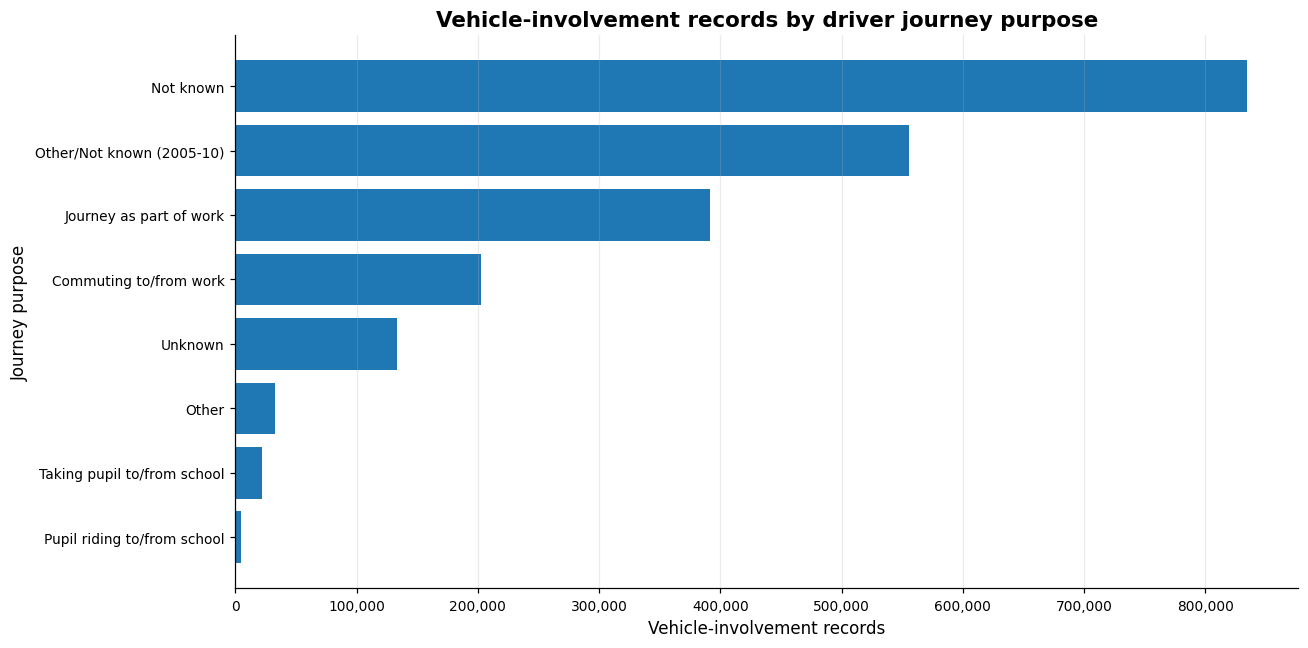

Interpretation: the result describes the purpose distribution among accident-involved vehicles, not the comparative risk of each journey purpose.


In [39]:
journey_pd = (
    vehicles.groupBy("Journey_Purpose_of_Driver").count()
    .orderBy(F.desc("count")).limit(12).toPandas().sort_values("count")
)
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(journey_pd["Journey_Purpose_of_Driver"], journey_pd["count"])
ax.set_title("Vehicle-involvement records by driver journey purpose")
ax.set_xlabel("Vehicle-involvement records"); ax.set_ylabel("Journey purpose")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.grid(axis="x")
plt.tight_layout(); plt.show()
print("Interpretation: the result describes the purpose distribution among accident-involved vehicles, not the comparative risk of each journey purpose.")

## 40. Vehicle type within accident-severity groups

**What this graph shows:** within each accident-severity category, the percentage distribution of vehicle involvement types in the matched subset. The analysis joins vehicle records to accident severity and therefore remains at vehicle-involvement grain. It does not count unique accidents by vehicle type.

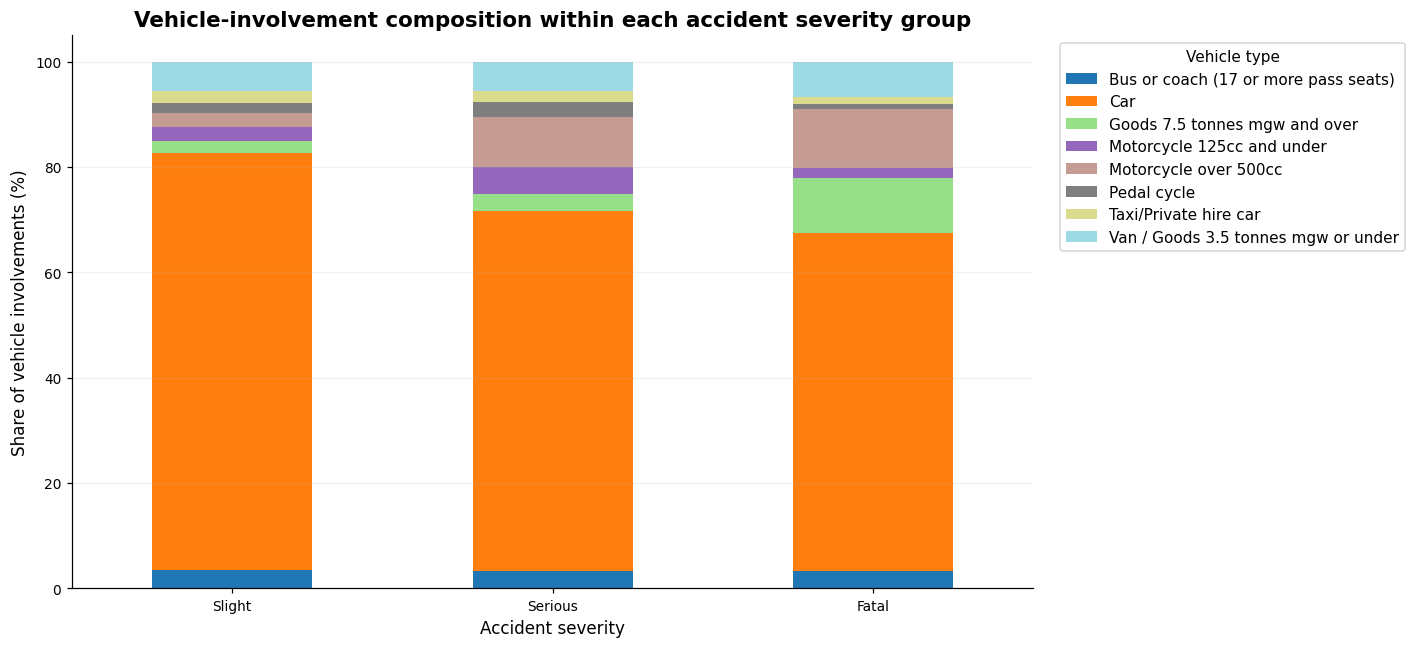

Interpretation: the bars compare vehicle-type mix within the matched severity groups. Because a collision can involve several vehicle rows, the denominator is vehicle involvements, not accidents.


In [40]:
vehicle_severity = (
    vehicles_overlap.join(
        accidents.select("Accident_Index", "Accident_Severity"),
        "Accident_Index", "inner"
    )
    .filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .groupBy("Accident_Severity", "Vehicle_Type").count()
    .toPandas()
)
# Keep the most common vehicle types overall, then normalize within severity.
top_vehicle_types = vehicle_severity.groupby("Vehicle_Type")["count"].sum().nlargest(8).index
vs = vehicle_severity[vehicle_severity["Vehicle_Type"].isin(top_vehicle_types)]
vs_pivot = vs.pivot(index="Accident_Severity", columns="Vehicle_Type", values="count").fillna(0)
vs_pct = vs_pivot.div(vs_pivot.sum(axis=1), axis=0) * 100
vs_pct = vs_pct.reindex(["Slight", "Serious", "Fatal"])
ax = vs_pct.plot(kind="bar", stacked=True, figsize=(13, 6), colormap="tab20")
ax.set_title("Vehicle-involvement composition within each accident severity group")
ax.set_xlabel("Accident severity"); ax.set_ylabel("Share of vehicle involvements (%)")
ax.legend(title="Vehicle type", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=.2); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Interpretation: the bars compare vehicle-type mix within the matched severity groups. Because a collision can involve several vehicle rows, the denominator is vehicle involvements, not accidents.")

## 41. Correlation among numeric accident characteristics

**What this graph shows:** Spearman rank correlations among speed limit, number of vehicles and number of casualties. Spearman correlation captures monotonic association and is less dependent on normal-distribution assumptions. It does not imply causation.

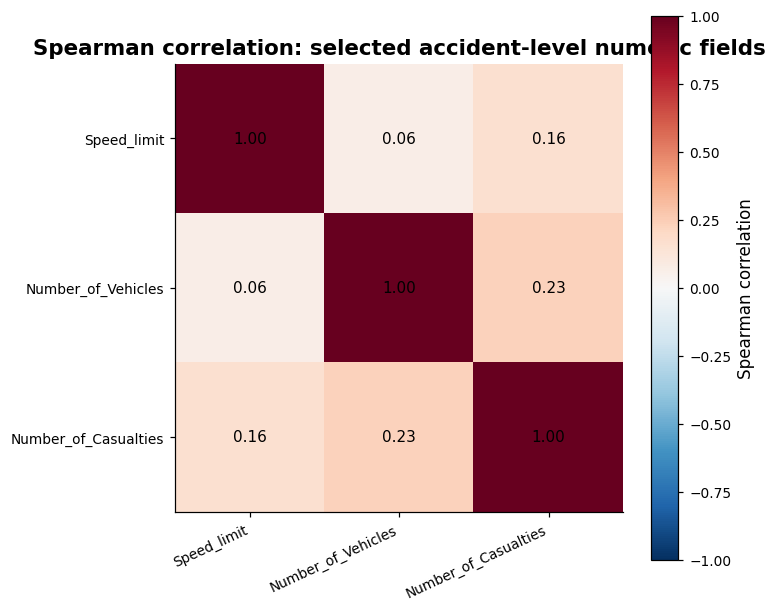

Interpretation: values near +1 indicate positive monotonic association, values near -1 indicate negative association, and values near 0 indicate weak monotonic association. The matrix is based on a sample of complete records.


In [41]:
numeric_sample = (
    accidents.select("Speed_limit", "Number_of_Vehicles", "Number_of_Casualties")
    .dropna().sample(False, .10, seed=23).limit(150000).toPandas()
)
correlation = numeric_sample.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(correlation.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns))); ax.set_xticklabels(correlation.columns, rotation=25, ha="right")
ax.set_yticks(range(len(correlation.index))); ax.set_yticklabels(correlation.index)
for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Spearman correlation: selected accident-level numeric fields")
fig.colorbar(im, ax=ax, label="Spearman correlation")
plt.tight_layout(); plt.show()
print("Interpretation: values near +1 indicate positive monotonic association, values near -1 indicate negative association, and values near 0 indicate weak monotonic association. The matrix is based on a sample of complete records.")

## 42. Statistical test: weather condition and accident severity

A chi-square test of independence tests whether the distribution of severity differs across weather categories. The contingency table is generated with Spark and reduced to category counts before SciPy computes the test. Cramér’s V is reported as an effect-size measure. A statistically significant result does not establish a causal weather effect.

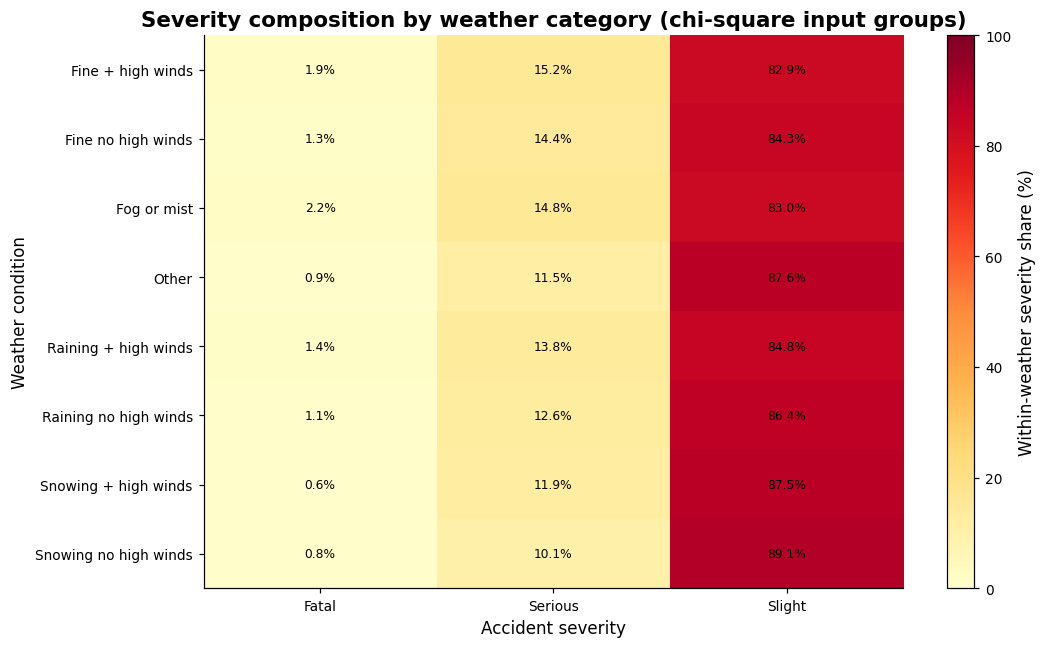

Chi-square statistic: 1,436.02
Degrees of freedom: 14
p-value: 2.8550e-298
Cramér's V: 0.0189
Interpretation: There is statistical evidence of association in this dataset (p < 0.05).
Effect size should be judged using Cramér's V; a very small p-value can occur with large datasets even when the association is weak.


In [42]:
weather_ct_pd = (
    accidents.filter(
        F.col("Accident_Severity").isin("Fatal", "Serious", "Slight") &
        (~F.col("Weather_Conditions").isin("Unknown", "NA"))
    )
    .groupBy("Weather_Conditions", "Accident_Severity").count().toPandas()
)
weather_ct = weather_ct_pd.pivot(index="Weather_Conditions", columns="Accident_Severity", values="count").fillna(0)
# Keep only weather groups with a minimum sample size.
weather_ct = weather_ct.loc[weather_ct.sum(axis=1) >= 500]
chi2, p_value, dof, expected = chi2_contingency(weather_ct.values)
n = weather_ct.values.sum()
min_dim = min(weather_ct.shape[0] - 1, weather_ct.shape[1] - 1)
cramers_v = math.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan

fig, ax = plt.subplots(figsize=(10, 6))
severity_pct_weather = weather_ct.div(weather_ct.sum(axis=1), axis=0) * 100
im = ax.imshow(severity_pct_weather.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)
ax.set_xticks(range(len(severity_pct_weather.columns))); ax.set_xticklabels(severity_pct_weather.columns)
ax.set_yticks(range(len(severity_pct_weather.index))); ax.set_yticklabels(severity_pct_weather.index)
for i in range(severity_pct_weather.shape[0]):
    for j in range(severity_pct_weather.shape[1]):
        ax.text(j, i, f"{severity_pct_weather.iloc[i,j]:.1f}%", ha="center", va="center", fontsize=8)
ax.set_title("Severity composition by weather category (chi-square input groups)")
ax.set_xlabel("Accident severity"); ax.set_ylabel("Weather condition")
fig.colorbar(im, ax=ax, label="Within-weather severity share (%)")
plt.tight_layout(); plt.show()

print(f"Chi-square statistic: {chi2:,.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.4e}")
print(f"Cramér's V: {cramers_v:.4f}")
print("Interpretation:", "There is statistical evidence of association in this dataset (p < 0.05)." if p_value < .05 else "The test does not show sufficient evidence of association at the 5% level.")
print("Effect size should be judged using Cramér's V; a very small p-value can occur with large datasets even when the association is weak.")

## 43. Statistical test: road-surface condition and accident severity

This second chi-square analysis tests whether severity distribution differs across recorded road-surface conditions. Rare surface categories are excluded from the statistical test when their total count is below 500 to reduce sparse-cell problems.

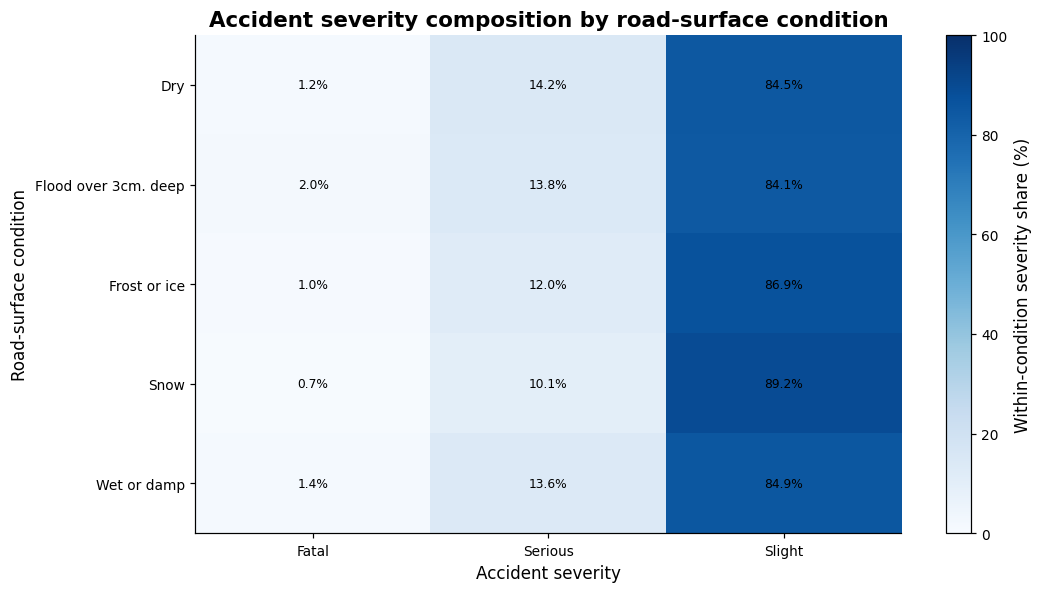

Chi-square statistic: 568.71
Degrees of freedom: 8
p-value: 1.2428e-117
Cramér's V: 0.0118
Interpretation: The severity distribution is statistically associated with road-surface category in this dataset.
Association is not causation; road type, weather, lighting, traffic and speed environment may also differ across surface groups.


In [43]:
surface_ct_pd = (
    accidents.filter(
        F.col("Accident_Severity").isin("Fatal", "Serious", "Slight") &
        (~F.col("Road_Surface_Conditions").isin("Unknown", "NA"))
    )
    .groupBy("Road_Surface_Conditions", "Accident_Severity").count().toPandas()
)
surface_ct = surface_ct_pd.pivot(index="Road_Surface_Conditions", columns="Accident_Severity", values="count").fillna(0)
surface_ct = surface_ct.loc[surface_ct.sum(axis=1) >= 500]
chi2_surface, p_surface, dof_surface, expected_surface = chi2_contingency(surface_ct.values)
n_surface = surface_ct.values.sum()
min_dim_surface = min(surface_ct.shape[0]-1, surface_ct.shape[1]-1)
cramers_v_surface = math.sqrt(chi2_surface/(n_surface*min_dim_surface)) if min_dim_surface > 0 else np.nan

surface_pct = surface_ct.div(surface_ct.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(surface_pct.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(surface_pct.columns))); ax.set_xticklabels(surface_pct.columns)
ax.set_yticks(range(len(surface_pct.index))); ax.set_yticklabels(surface_pct.index)
for i in range(surface_pct.shape[0]):
    for j in range(surface_pct.shape[1]):
        ax.text(j, i, f"{surface_pct.iloc[i,j]:.1f}%", ha="center", va="center", fontsize=8)
ax.set_title("Accident severity composition by road-surface condition")
ax.set_xlabel("Accident severity"); ax.set_ylabel("Road-surface condition")
fig.colorbar(im, ax=ax, label="Within-condition severity share (%)")
plt.tight_layout(); plt.show()

print(f"Chi-square statistic: {chi2_surface:,.2f}")
print(f"Degrees of freedom: {dof_surface}")
print(f"p-value: {p_surface:.4e}")
print(f"Cramér's V: {cramers_v_surface:.4f}")
print("Interpretation:", "The severity distribution is statistically associated with road-surface category in this dataset." if p_surface < .05 else "The test does not show sufficient evidence of association at the 5% level.")
print("Association is not causation; road type, weather, lighting, traffic and speed environment may also differ across surface groups.")

## 44. Long-run monthly trend and 12-month moving average

This chart uses year-month accident counts. The moving average reduces short-term fluctuations and makes the longer movement easier to interpret. The date axis is based on the parsed accident date, not only the source year field.

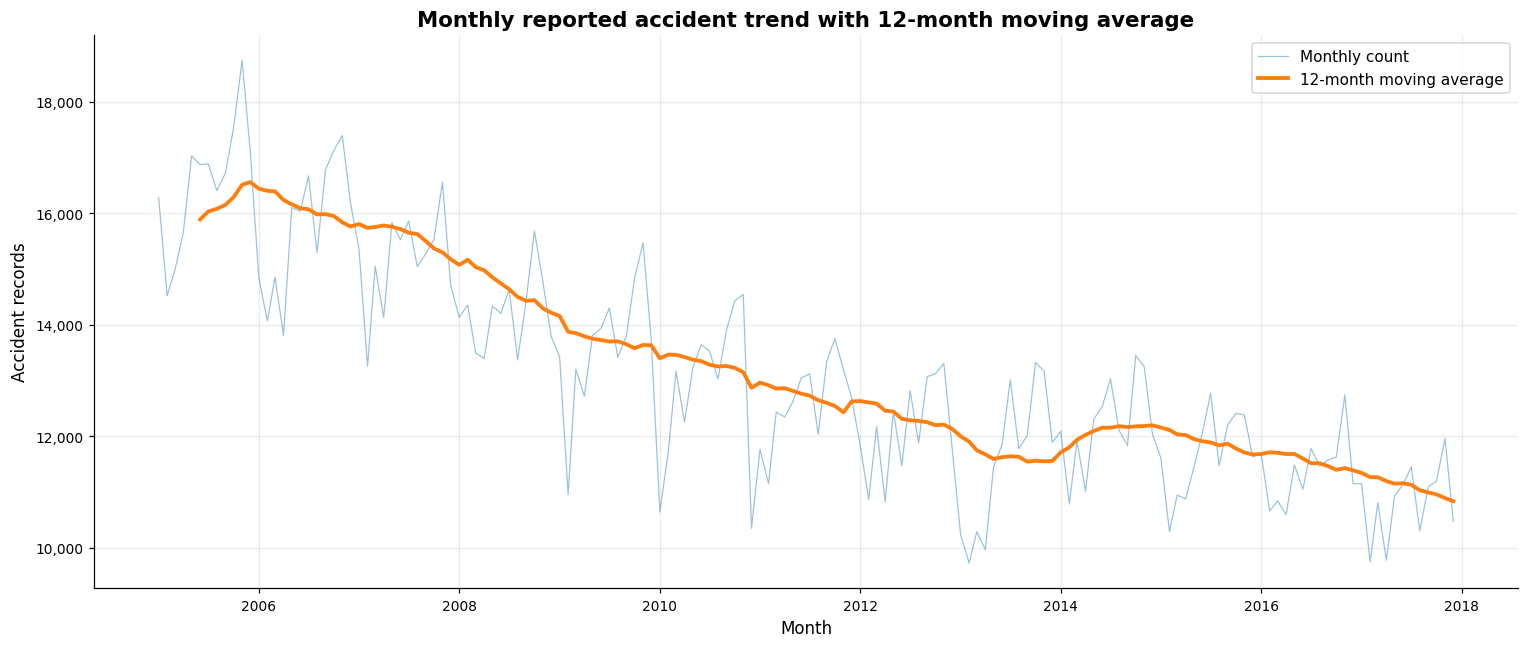

Interpretation: the moving average smooths the seasonal cycle. It highlights long-run changes in recorded accidents without implying an exposure-adjusted safety rate.


In [44]:
monthly_series_pd = (
    accidents.filter(F.col("Accident_Date").isNotNull())
    .groupBy(F.date_trunc("month", F.col("Accident_Date")).alias("Month_Start"))
    .count().orderBy("Month_Start").toPandas()
)
monthly_series_pd["MA_12"] = monthly_series_pd["count"].rolling(12, min_periods=6).mean()
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(monthly_series_pd["Month_Start"], monthly_series_pd["count"], linewidth=.8, alpha=.45, label="Monthly count")
ax.plot(monthly_series_pd["Month_Start"], monthly_series_pd["MA_12"], linewidth=2.5, label="12-month moving average")
ax.set_title("Monthly reported accident trend with 12-month moving average")
ax.set_xlabel("Month"); ax.set_ylabel("Accident records")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
print("Interpretation: the moving average smooths the seasonal cycle. It highlights long-run changes in recorded accidents without implying an exposure-adjusted safety rate.")

## 45. Optional predictive analysis: define the target and sample

**Optional advanced section.** This model predicts whether an accident is Fatal/Serious (`1`) or Slight (`0`) from selected accident circumstances. It intentionally excludes `Number_of_Casualties` because casualty count is closely tied to the severity outcome and could create target leakage. The model is a baseline association model, not a causal or operational safety system. A stratified class-weight adjustment is used to reduce the impact of class imbalance.

In [45]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

model_categorical = [
    "Road_Type", "Weather_Conditions", "Road_Surface_Conditions",
    "Light_Conditions", "Urban_or_Rural_Area", "Junction_Detail", "Day_of_Week"
]
model_numeric = ["Speed_limit", "Hour", "Month", "Number_of_Vehicles"]

model_base = (
    accidents.filter(F.col("Accident_Severity").isin("Fatal", "Serious", "Slight"))
    .withColumn("label", F.when(F.col("Accident_Severity").isin("Fatal", "Serious"), 1.0).otherwise(0.0))
    .select("label", *model_categorical, *model_numeric)
    .sample(False, 0.35, seed=42)
)

train_raw, test_raw = model_base.randomSplit([0.8, 0.2], seed=42)
class_counts = train_raw.groupBy("label").count().collect()
class_count_map = {float(r["label"]): int(r["count"]) for r in class_counts}
neg_n = class_count_map.get(0.0, 1)
pos_n = class_count_map.get(1.0, 1)
total_n = neg_n + pos_n

train_raw = train_raw.withColumn(
    "class_weight",
    F.when(F.col("label") == 1.0, F.lit(total_n / (2 * pos_n)))
     .otherwise(F.lit(total_n / (2 * neg_n)))
)

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in model_categorical]
encoder = OneHotEncoder(
    inputCols=[f"{c}_idx" for c in model_categorical],
    outputCols=[f"{c}_oh" for c in model_categorical],
    handleInvalid="keep"
)
imputer = Imputer(
    inputCols=model_numeric,
    outputCols=[f"{c}_imputed" for c in model_numeric],
    strategy="median"
)
assembler = VectorAssembler(
    inputCols=[f"{c}_oh" for c in model_categorical] + [f"{c}_imputed" for c in model_numeric],
    outputCol="features",
    handleInvalid="keep"
)
logistic = LogisticRegression(
    labelCol="label", featuresCol="features", weightCol="class_weight",
    maxIter=25, regParam=0.05, elasticNetParam=0.0
)
pipeline = Pipeline(stages=indexers + [encoder, imputer, assembler, logistic])
model = pipeline.fit(train_raw)

# Add class weights to the test data for consistent pipeline columns (the model ignores test weights).
test_data = test_raw.withColumn("class_weight", F.lit(1.0))
predictions = model.transform(test_data).select("label", "prediction", "probability")

roc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
# Evaluators require rawPrediction; retain it for metrics.
predictions_full = model.transform(test_data)
auc_roc = roc_eval.evaluate(predictions_full)
auc_pr = pr_eval.evaluate(predictions_full)
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
f1_score = f1_eval.evaluate(predictions_full)

print(f"Training rows: {train_raw.count():,}")
print(f"Testing rows:  {test_raw.count():,}")
print(f"Positive class (Fatal/Serious) training rows: {pos_n:,}")
print(f"ROC-AUC: {auc_roc:.4f}")
print(f"PR-AUC:  {auc_pr:.4f}")
print(f"Weighted F1: {f1_score:.4f}")

Training rows: 573,992
Testing rows:  143,341
Positive class (Fatal/Serious) training rows: 88,153
ROC-AUC: 0.6234
PR-AUC:  0.2218
Weighted F1: 0.6463


## 46. Model evaluation: confusion matrix

**What this graph shows:** test-set predictions compared with actual classes. The positive class is Fatal/Serious and the negative class is Slight. A confusion matrix shows the trade-off between false alarms and missed severe cases. It should be read alongside recall and precision, not accuracy alone.

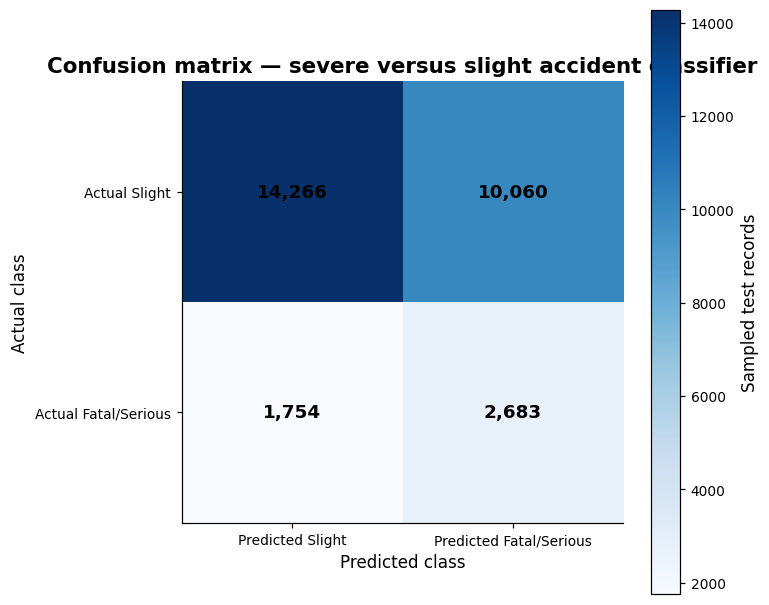

               precision    recall  f1-score   support

       Slight       0.89      0.59      0.71     24326
Fatal/Serious       0.21      0.60      0.31      4437

     accuracy                           0.59     28763
    macro avg       0.55      0.60      0.51     28763
 weighted avg       0.79      0.59      0.65     28763

Interpretation: false negatives are actual Fatal/Serious accidents predicted as Slight. In safety-oriented applications, recall for the severe class is particularly important, but this model is only an academic baseline.


In [46]:
from sklearn.metrics import confusion_matrix, classification_report

pred_sample = predictions_full.select("label", "prediction").sample(False, .20, seed=43).limit(100000).toPandas()
y_true = pred_sample["label"].astype(int)
y_pred = pred_sample["prediction"].astype(int)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted Slight", "Predicted Fatal/Serious"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual Slight", "Actual Fatal/Serious"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_title("Confusion matrix — severe versus slight accident classifier")
ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
fig.colorbar(im, ax=ax, label="Sampled test records")
plt.tight_layout(); plt.show()
print(classification_report(y_true, y_pred, target_names=["Slight", "Fatal/Serious"], zero_division=0))
print("Interpretation: false negatives are actual Fatal/Serious accidents predicted as Slight. In safety-oriented applications, recall for the severe class is particularly important, but this model is only an academic baseline.")

## 47. Model evaluation: ROC curve

**What this graph shows:** the true-positive rate versus false-positive rate across classification thresholds. A curve closer to the top-left indicates stronger ranking ability. The diagonal is the reference for random ranking. The reported ROC-AUC is computed on the held-out test data.

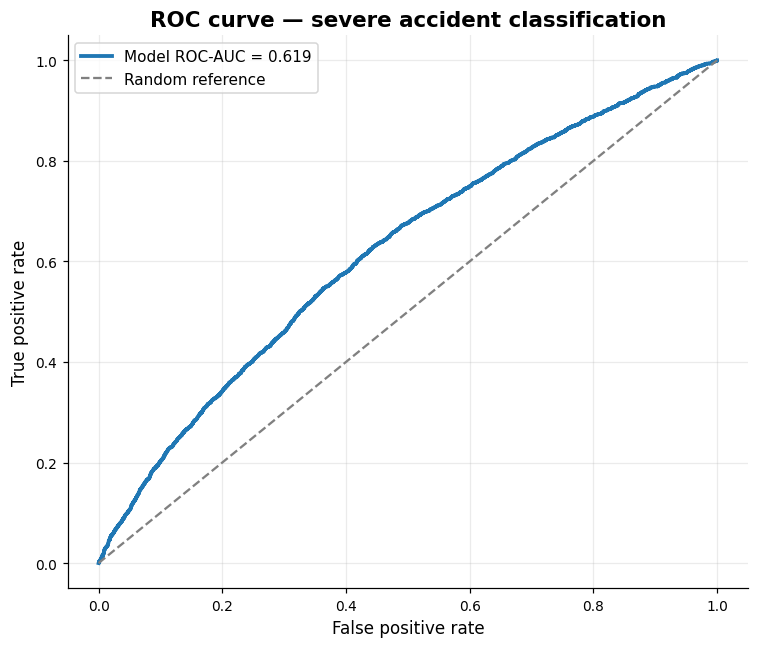

Interpretation: ROC-AUC measures the model's ability to rank a randomly chosen severe accident above a randomly chosen slight accident. It does not measure calibration or prove causal drivers.


In [47]:
from sklearn.metrics import roc_curve, roc_auc_score

roc_sample = predictions_full.select("label", "probability").sample(False, .15, seed=44).limit(100000).toPandas()
roc_y = roc_sample["label"].astype(int).values
roc_scores = np.array([float(v[1]) for v in roc_sample["probability"]])
fpr, tpr, thresholds = roc_curve(roc_y, roc_scores)
roc_auc_sample = roc_auc_score(roc_y, roc_scores)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, linewidth=2.5, label=f"Model ROC-AUC = {roc_auc_sample:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random reference")
ax.set_title("ROC curve — severe accident classification")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
print("Interpretation: ROC-AUC measures the model's ability to rank a randomly chosen severe accident above a randomly chosen slight accident. It does not measure calibration or prove causal drivers.")

## 48. Model coefficients: strongest positive and negative associations

The logistic-regression coefficients are shown as model associations on the transformed feature vector. One-hot encoded categorical features are not fully decoded here, so this chart shows coefficient magnitudes by feature-vector position only if metadata is unavailable. Interpret signs and magnitudes cautiously, especially because one-hot encoding and correlated predictors affect coefficient meaning.

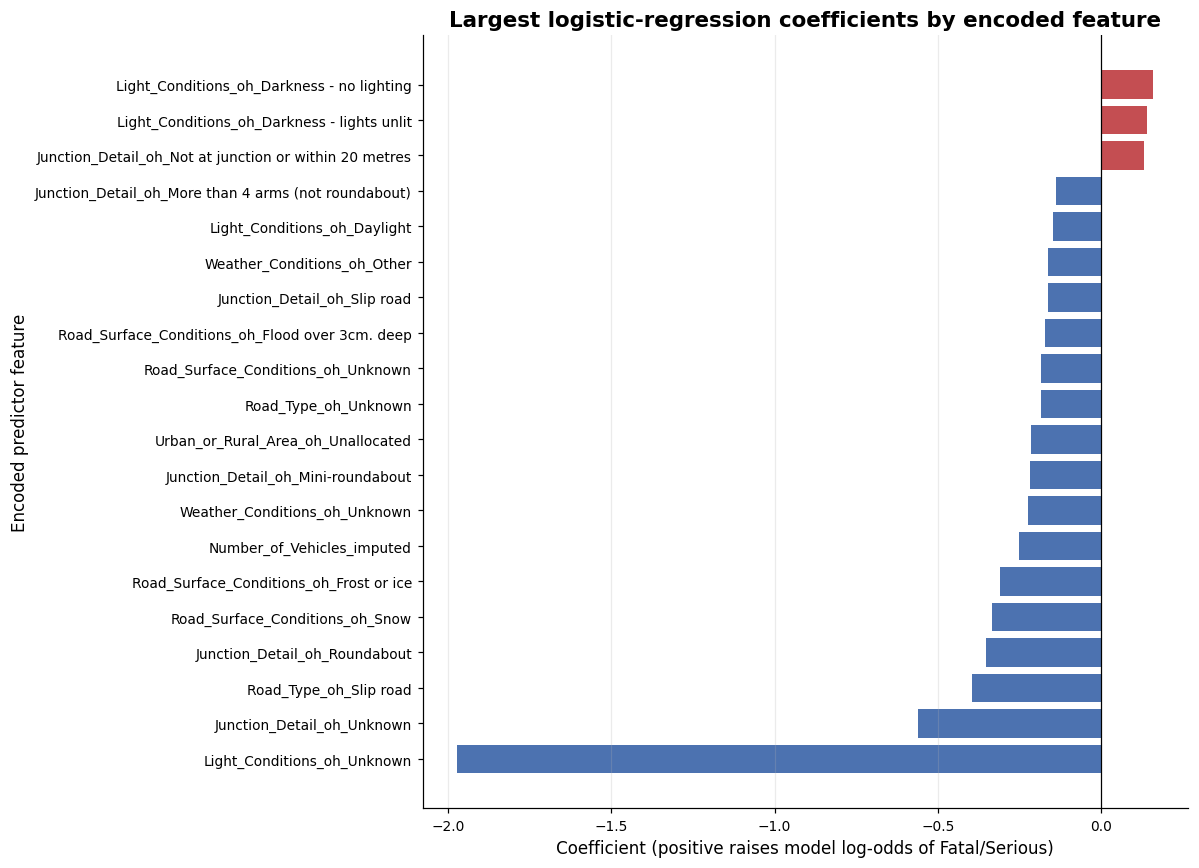

Interpretation: positive coefficients are associated with higher model log-odds of the severe class; negative coefficients with lower log-odds. These are conditional model associations, not causal effects. One-hot encoded features should be interpreted relative to their reference coding and other predictors.


In [48]:
# Access the fitted LogisticRegressionModel at the end of the pipeline.
lr_model = model.stages[-1]
coefficients = np.array(lr_model.coefficients.toArray())

# Decode Spark's feature-vector metadata so coefficient labels are meaningful.
feature_metadata = predictions_full.schema["features"].metadata.get("ml_attr", {})
attribute_groups = feature_metadata.get("attrs", {})
feature_label_map = {}
for group in attribute_groups.values():
    for attribute in group:
        feature_label_map[int(attribute["idx"])] = attribute.get("name", f"feature_{attribute['idx']}")

feature_names = [feature_label_map.get(i, f"feature_{i}") for i in range(len(coefficients))]
coef_pd = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
coef_pd["Abs_Coefficient"] = coef_pd["Coefficient"].abs()
coef_top = coef_pd.nlargest(20, "Abs_Coefficient").sort_values("Coefficient")

fig, ax = plt.subplots(figsize=(11, 8))
colors = np.where(coef_top["Coefficient"] >= 0, "#c44e52", "#4c72b0")
ax.barh(coef_top["Feature"], coef_top["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=.8)
ax.set_title("Largest logistic-regression coefficients by encoded feature")
ax.set_xlabel("Coefficient (positive raises model log-odds of Fatal/Serious)")
ax.set_ylabel("Encoded predictor feature")
ax.grid(axis="x", alpha=.25); plt.tight_layout(); plt.show()
print("Interpretation: positive coefficients are associated with higher model log-odds of the severe class; negative coefficients with lower log-odds. These are conditional model associations, not causal effects. One-hot encoded features should be interpreted relative to their reference coding and other predictors.")

## 49. Evidence-based project outcomes

This section calculates concise findings directly from the Spark results. It avoids hard-coding a conclusion: the values are generated from the current dataset and cleaning rules.

In [49]:
annual_rows = annual_accidents.sort_values("Year")
first_row = annual_rows.iloc[0]
last_row = annual_rows.iloc[-1]
peak_row = annual_rows.loc[annual_rows["Accidents"].idxmax()]
lowest_row = annual_rows.loc[annual_rows["Accidents"].idxmin()]

severity_totals = severity_pd.set_index("Accident_Severity")["count"].to_dict()
known_severity_total = sum(severity_totals.values())
severe_total = severity_totals.get("Fatal", 0) + severity_totals.get("Serious", 0)
severe_share = 100 * severe_total / known_severity_total if known_severity_total else np.nan

peak_month = monthly_pd.loc[monthly_pd["count"].idxmax()]
peak_weekday = weekday_pd.loc[weekday_pd["count"].idxmax()]
peak_hour = hour_pd.loc[hour_pd["count"].idxmax()]

pct_change_total = 100 * (last_row["Accidents"] / first_row["Accidents"] - 1)

findings = [
    f"The accident file contains **{accident_clean_count:,}** accident records covering **{int(annual_rows['Year'].min())}–{int(annual_rows['Year'].max())}**.",
    f"The highest annual accident count in the file is **{int(peak_row['Year'])}** ({int(peak_row['Accidents']):,}); the lowest is **{int(lowest_row['Year'])}** ({int(lowest_row['Accidents']):,}).",
    f"Recorded accident counts changed by **{pct_change_total:.1f}%** between {int(first_row['Year'])} and {int(last_row['Year'])}.",
    f"Fatal and Serious records represent **{severe_share:.2f}%** of records with one of the three known severity categories.",
    f"The most-recorded month across all years is **{peak_month['Month_Name']}**; the most-recorded weekday is **{peak_weekday['Day_of_Week']}**; the most-recorded hour is **{int(peak_hour['Hour']):02d}:00**."
]

print("KEY FINDINGS")
print("=" * 75)
for i, finding in enumerate(findings, 1):
    display(Markdown(f"{i}. {finding}"))

KEY FINDINGS


1. The accident file contains **2,047,256** accident records covering **2005–2017**.

2. The highest annual accident count in the file is **2005** (198,735); the lowest is **2017** (129,982).

3. Recorded accident counts changed by **-34.6%** between 2005 and 2017.

4. Fatal and Serious records represent **15.27%** of records with one of the three known severity categories.

5. The most-recorded month across all years is **Nov**; the most-recorded weekday is **Friday**; the most-recorded hour is **17:00**.

## 51. Interpretation, limitations and recommendations

### What the analysis can support

- A descriptive account of reported personal-injury road collisions in Great Britain across the accident file's 2005–2017 period.
- Comparisons of recorded accident severity across time, weather, light, road-surface, road-type, speed-limit and urban/rural categories.
- A description of casualties, vehicle involvements, driver age-band records and vehicle characteristics.
- Statistical evidence about association between selected categorical conditions and severity.
- A baseline machine-learning exercise distinguishing Fatal/Serious from Slight records using available accident circumstances.

### What the analysis cannot establish

- It cannot calculate the proportion of unlicensed drivers: neither file has a driving-licence status field.
- It cannot calculate actual crash risk per mile, trip, driver, vehicle or road segment because exposure denominators are not part of these two CSVs.
- It cannot infer causation from correlation, chi-square tests or predictive model coefficients.
- It cannot interpret raw district, vehicle-type, sex or age-band counts as risk rankings without population or travel-exposure denominators.
- It cannot treat the vehicle file as a complete mirror of all accident IDs. Linkage is incomplete in this Kaggle extract and differs by year.
- It does not cover every crash: the official STATS19 road-safety collection covers police-reported personal-injury collisions on public roads.

### Recommendations for a stronger follow-up

1. Obtain traffic-flow, road-length or vehicle-mile exposure data to calculate rates rather than counts.
2. Use the casualty-level file if the next project stage needs injury severity by casualty age, sex or road-user type.
3. Use current official DfT data for an updated period, while documenting changes in coding and data collection.
4. Examine missingness and linkage by year before comparing vehicle characteristics across periods.
5. Use the model only as an academic baseline. Any operational safety model would require external validation, calibration, bias assessment and careful governance.

### Final conclusion

The notebook demonstrates a reproducible big-data workflow: source acquisition, Spark ingestion, data validation, cleaning, feature engineering, temporal and categorical exploration, geospatial visualization, statistical testing, optional classification and presentation through an interactive dashboard. The most important analytical discipline is to distinguish **record counts**, **severity composition**, **vehicle involvements** and **exposure-adjusted risk**. They answer different questions and must not be interchanged.

## 52. References and data provenance

1. **Kaggle dataset:** [UK Road Safety: Traffic Accidents and Vehicles](https://www.kaggle.com/datasets/tsiaras/uk-road-safety-accidents-and-vehicles). Dataset description identifies `Accident_Information.csv` as accident-level data for 2005–2017 and `Vehicle_Information.csv` as vehicle-level data for 2004–2016.
2. **UK Department for Transport:** [Road safety open data](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data). The official source describes record-level collision, vehicle and casualty data and explains that road-safety records cover police-reported personal-injury collisions on public roads.
3. **UK Department for Transport:** [Road safety statistics: guidance](https://www.gov.uk/guidance/road-accident-and-safety-statistics-guidance). Guidance on the STATS19 collection and interpretation.

**Reproducibility note:** The notebook downloads the Kaggle archive at runtime. The Kaggle API token is requested interactively and is not embedded in the `.ipynb` file. No data files are redistributed with this notebook.

## 53. Final interactive dashboard

The final dashboard consolidates a small set of complementary headline indicators: annual accident trend, severity composition, hour-of-day pattern, and leading road types. Unlike the earlier standalone analytical cells, this last section intentionally combines related headline views into one interactive dashboard for presentation.

In [50]:
# Build small summary data for Plotly. Spark does the aggregation; Plotly receives only compact results.
annual_dash = annual_accidents.copy()
severity_dash = severity_pd.copy()
hour_dash = hour_pd.copy()
road_dash = road_type_pd.sort_values("count", ascending=False).head(8).copy()

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Annual reported accidents (2005–2017)",
        "Accident severity composition",
        "Accident records by hour",
        "Most common road types"
    ),
    specs=[[{"type": "xy"}, {"type": "domain"}], [{"type": "xy"}, {"type": "xy"}]],
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

fig.add_trace(
    go.Scatter(x=annual_dash["Year"], y=annual_dash["Accidents"], mode="lines+markers", name="Annual accidents"),
    row=1, col=1
)
fig.add_trace(
    go.Pie(labels=severity_dash["Accident_Severity"], values=severity_dash["count"], hole=.55, name="Severity"),
    row=1, col=2
)
fig.add_trace(
    go.Bar(x=hour_dash["Hour"], y=hour_dash["count"], name="By hour"),
    row=2, col=1
)
fig.add_trace(
    go.Bar(x=road_dash["count"], y=road_dash["Road_Type"], orientation="h", name="Road type"),
    row=2, col=2
)

fig.update_layout(
    title={"text": "UK ROAD SAFETY ANALYTICS — EXECUTIVE DASHBOARD", "x": .5},
    height=850,
    template="plotly_white",
    showlegend=False,
    margin=dict(t=100, l=50, r=50, b=50)
)
fig.update_xaxes(title_text="Year", row=1, col=1)
fig.update_yaxes(title_text="Accident records", row=1, col=1, tickformat=",")
fig.update_xaxes(title_text="Hour of day", row=2, col=1)
fig.update_yaxes(title_text="Accident records", row=2, col=1, tickformat=",")
fig.update_xaxes(title_text="Vehicle-involvement accident records", row=2, col=2, tickformat=",")
fig.update_yaxes(title_text="Road type", row=2, col=2)
fig.show()